<a href="https://colab.research.google.com/github/mahaairshad-shu/Hackathon-SERG_SHU_UoM_Nov2026/blob/main/BlueTrident_IMUs_Action_Recognition_Tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

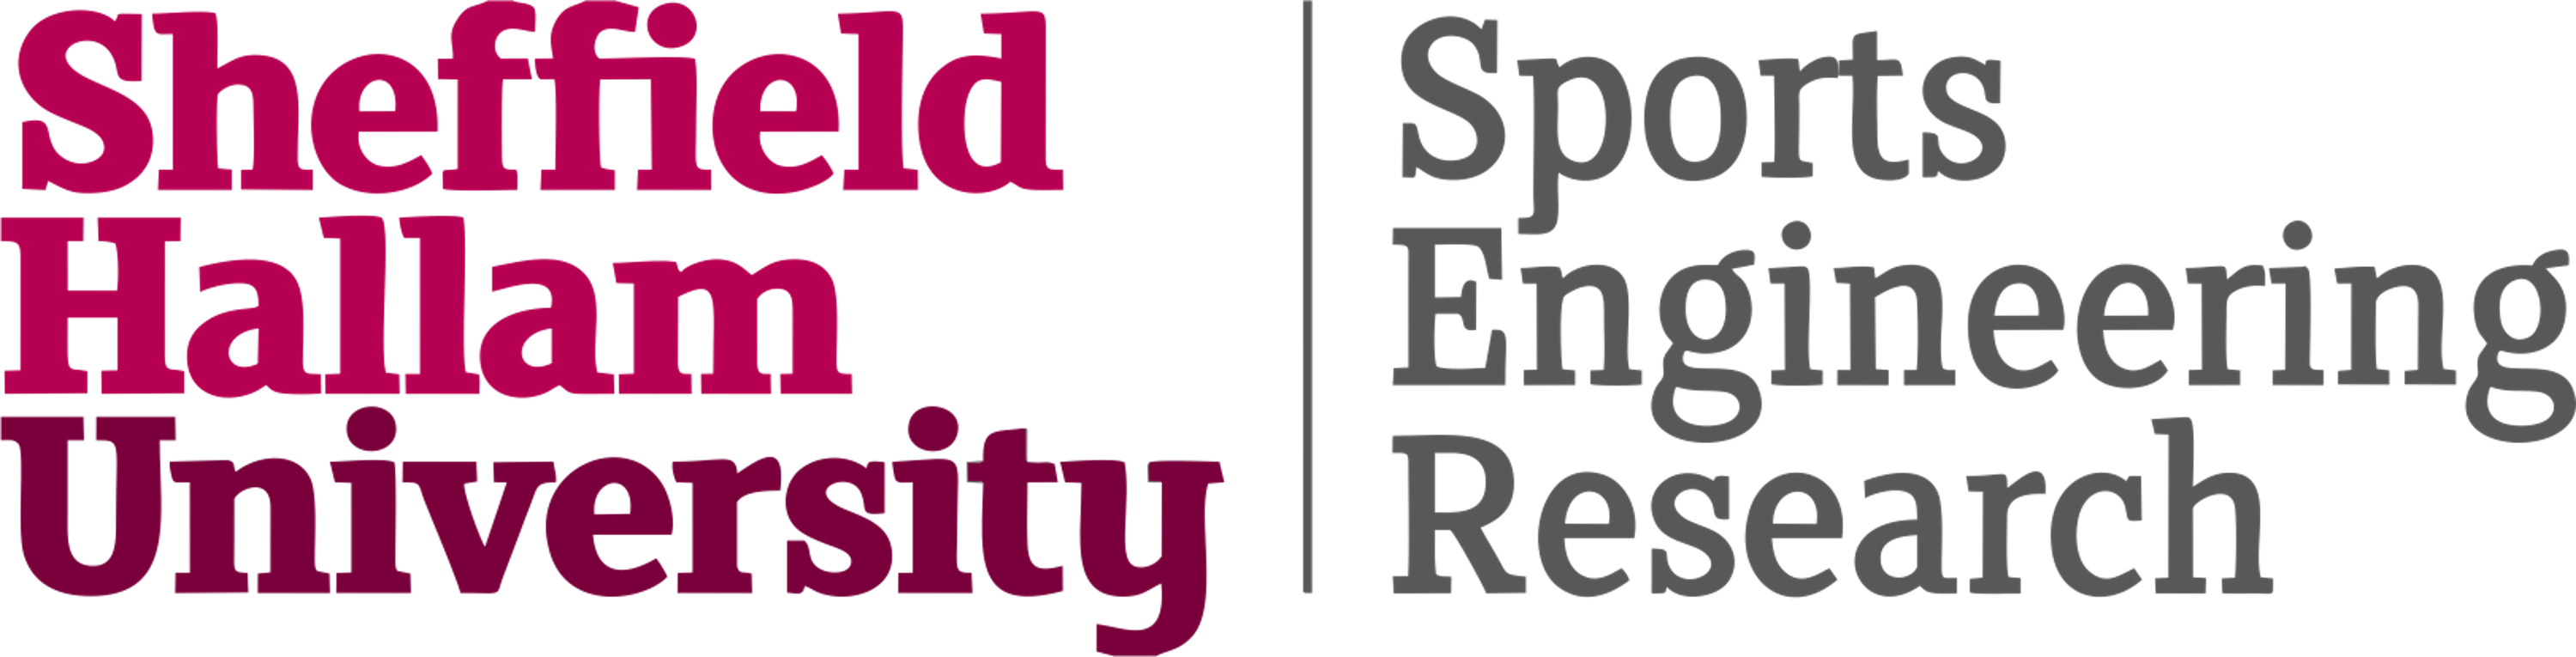

# Recognising movements with Vicon Blue Trident IMUs
### Hackathon tutorial: from your own sensor recordings to a trained movement classifier (Random Forest and CNN)

You record movements with wearable **Blue Trident IMUs**, clean the signals, and train models that recognise which movement is being performed.

The notebook comes with an **example dataset** (7 sensors on the lower body, 8 movements), but it is written for **your own recordings**: different movements, file names, sensor positions or number of sensors.

| Part | What happens |
|---|---|
| 0 | About the sensor, how to record and organise files, ⚙️ **settings**, upload |
| 1 | **Data cleaning**: read files, **Butterworth filter**, cut away the still periods, downsample |
| 2 | **Pre-processing**: label, cut into **sliding windows**, normalise |
| 3 | **Model training**: a Random Forest baseline and a **1D CNN** |
| 4 | **Model testing**: evaluate on your test files, run the model over whole recordings |

> 🧭 **Using your own data**
> 1. Record each movement in its own recording (see the tips in 0.4).
> 2. Put the CSV files in a `train/` and a `test/` folder, zip both (diagram in 0.4).
> 3. Edit the ⚙️ **Settings** cell (0.6), then *Runtime → Run all*. Upload the zips when asked.
> 4. Read each ✏️ box to see whether anything else needs adjusting.

### ✏️ Quick reference: what to change for your data

| Your situation | What to change | Where |
|---|---|---|
| Different movements | **nothing**: names come from the file names | – |
| Different number / position of sensors | **nothing**: sensors come from the file names. Optional: `SENSORS_TO_USE` | ⚙️ Settings |
| Files named differently | the `parse_filename()` function | Part 1.1 |
| Signals look too noisy / too smooth | `FILTER_CUTOFF_HZ` (try it first with the slider) | 1.3 → ⚙️ Settings |
| The crop cuts in the wrong place | `REFERENCE_SENSOR`, `REFERENCE_SIGNAL`, `REFERENCE_PER_MOVEMENT`, `THRESHOLD_FRACTION`, or `MANUAL_CROPS` (try first with the explorer) | 1.4 → ⚙️ Settings |
| No still period at start/end of your recordings | `AUTO_CROP = False` | ⚙️ Settings |
| Your "standing still" movement has another name | nothing (detected automatically), or `REST_LABEL` | ⚙️ Settings |
| Very short or long movements | `WINDOW_S`, `STEP_S` | ⚙️ Settings |
| The CNN under- or over-fits | `EPOCHS`, `AUGMENT_COPIES`, the layers in `build_cnn()` | ⚙️ Settings, Part 3.2 |

---
## 0. Background and setup



### 0.1 The sensor: Vicon Blue Trident

The **Blue Trident** (Vicon / IMeasureU) is a small, lightweight wearable **Inertial Measurement Unit (IMU)**:

| Component | Measures | Range | Max sampling rate |
|---|---|---|---|
| Low-g accelerometer (3-axis) | Linear acceleration (m/s²) | ±16 g | 1125 Hz |
| High-g accelerometer (3-axis) | Large impacts (m/s²) | ±200 g | 1600 Hz |
| Gyroscope (3-axis) | Angular velocity (deg/s) | ±2000 °/s | 1125 Hz |
| Magnetometer (3-axis) | Magnetic field (µT) | ±4900 µT | 100 Hz |

It is waterproof (IP68), runs about 12 h on a charge, records to on-board memory and is set up with the **Capture.U** app.

The exported CSV files have 13 columns:
`time_s, ax, ay, az, gx, gy, gz, mx, my, mz, highg_ax, highg_ay, highg_az`.
We use only the **first 7**: time, the accelerometer (`ax, ay, az`) and the gyroscope (`gx, gy, gz`).

### 0.2 Sensor placement in the example dataset

| Name | Location |
|---|---|
| `SAC` | Sacrum (lower back / pelvis) |
| `LTHIGH`, `RTHIGH` | Outer side of the left / right thigh |
| `LSHANK`, `RSHANK` | Front of the lower left / right shin |
| `LFOOT`, `RFOOT` | Top of the left / right shoe (on the laces) |

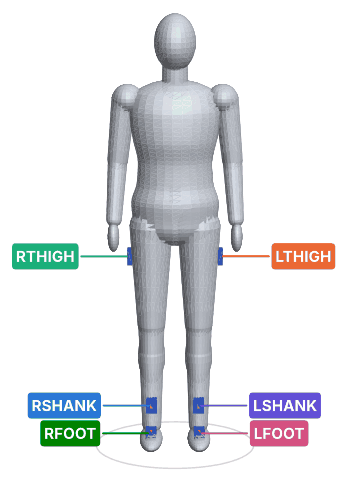

*Sensors are drawn 1.5× real size. If you place your sensors differently, the code does not need to know where they are; just give each a name.*

### 0.3 Sensor coordinate system

Each IMU measures along its **own axes**, which move with the body segment it is strapped to:

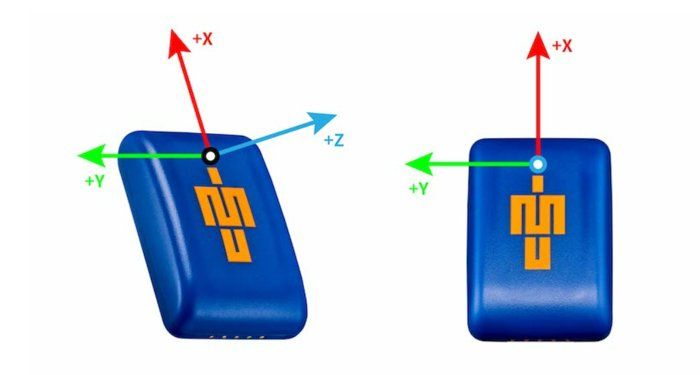

* **+X** (red): along the long side, pointing away from the end with the charging pins
* **+Y** (green): across the face, to the left when you look at the logo
* **+Z** (blue): out of the face (right-hand rule)

**Why this matters:** the accelerometer also feels **gravity**. A still sensor with +X pointing up reads `ax ≈ +9.81 m/s²`; upside down, `ax ≈ -9.81`. When a segment rotates, gravity moves between the axes, which is a strong clue for telling movements apart.

> 💡 How you orient each sensor does not matter, as long as it is **the same in every recording** (train and test).

### 0.4 How to record and organise your data

**Recording tips**
* **Stand still for ~2 s** at the start and end of every recording. The code uses these quiet periods to find where the movement starts and stops, and as examples of "not moving".
* **One movement per recording.** Each recording gives one CSV file per sensor.
* Record each movement **at least twice**: one recording for `train/`, another for `test/`. Only one recording? Put a **copy** of it in `test/` (the test then only checks that everything works, see Part 4).
* Record a **standing-still** movement too (e.g. `STATIC`).
* Use the **same sampling rate** for all sensors, and **start all sensors together**.

**File names and folders**

File names must contain the **movement** and the **sensor**: `BT_<MOVEMENT>_<SENSOR>.csv`, e.g. `BT_SQUAT_LTHIGH.csv` (movement names may contain `_`). Then zip the two folders and upload them in 0.7:

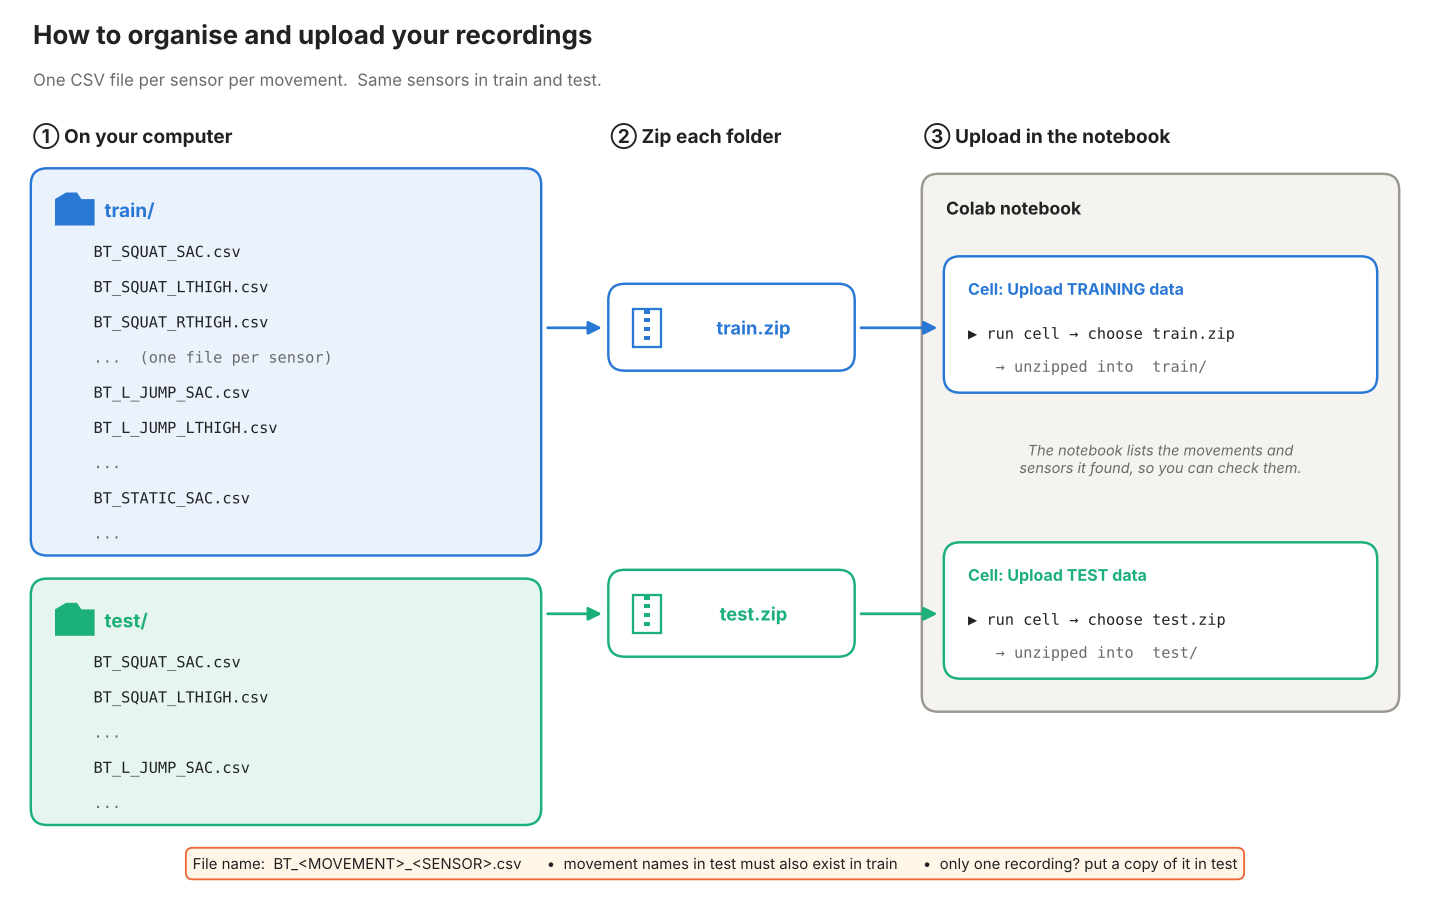

*Several recordings of the same movement in one set? Put each in its own sub-folder inside `train/` or `test/` (e.g. `train/session1/`, `train/session2/`).*

### 0.5 Setup: libraries

In [ ]:
import os, glob, zipfile, shutil, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from scipy.signal import butter, filtfilt, freqz
import ipywidgets as widgets
from IPython.display import display, HTML

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
AXIS_COLORS = ['#e34948', '#008300', '#2a78d6']   # x, y, z (same colours as the axis image)
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


### 0.6 ⚙️ Settings: the main cell to edit

Everything you may want to change is here, with a comment for each setting. **Start with the defaults**, look at the plots, and come back if needed.

In [ ]:
# =========================== ⚙️ SETTINGS ===========================

# ---------- Data ----------
TRAIN_DIR = 'train'          # folder for training files (sub-folders are searched too)
TEST_DIR  = 'test'           # folder for test files

# Columns to read from each CSV (0 = first column).
# Blue Trident export: time_s, ax, ay, az, gx, gy, gz, mx, my, mz, highg_ax, highg_ay, highg_az
COLUMNS_TO_USE = [0, 1, 2, 3, 4, 5, 6]
COLUMN_NAMES   = ['time_s', 'ax', 'ay', 'az', 'gx', 'gy', 'gz']   # keep these names

SENSORS_TO_USE = None        # None = all sensors found, or a list such as ['LTHIGH', 'RTHIGH']

# ---------- Part 1.3: Butterworth low-pass filter ----------
FILTER_CUTOFF_HZ = 1 #20        # frequencies above this are removed (human movement is mostly < 15-20 Hz)
FILTER_ORDER     = 4         # higher = sharper cut-off

# ---------- Part 1.4: cropping away the still periods ----------
AUTO_CROP          = True    # False = keep whole recordings
REFERENCE_SENSOR   = 'auto'  # sensor used to detect movement: 'auto' (the one that moves most) or a name, e.g. 'SAC'
REFERENCE_SIGNAL   = 'gyro'  # 'gyro' (rotation) or 'acc' (acceleration)
REFERENCE_PER_MOVEMENT = {}  # per-movement override, e.g. {'SQUAT': ('LTHIGH', 'acc'), 'L_JUMP': ('auto', 'acc')}
ENVELOPE_CUTOFF_HZ = 2.0     # how smooth the movement curve is (low-pass cut-off, Hz)
THRESHOLD_FRACTION = 0.10    # "moving" = above 10 % of the way from resting level to peak
PADDING_S          = 0.25    # extra seconds kept before and after the movement
STILL_LIMIT        = {'gyro': 20, 'acc': 1.0}  # below this peak (deg/s or m/s²) a recording counts as "still"
EDGE_TRIM_S        = 1.0     # for still recordings: seconds cut from start and end
MANUAL_CROPS       = {}      # fixed crop times, e.g. {('train', 'SQUAT'): (1.5, 5.0)}

# ---------- Part 1.5: downsampling ----------
TARGET_FS = 100              # Hz. Fewer samples = faster training; must be > 2 x FILTER_CUTOFF_HZ

# ---------- Part 2: windows ----------
WINDOW_S      = 1.0          # window length (s): roughly the length of your shortest movement
STEP_S        = 0.1          # how far the window slides each step (s)
REST_LABEL    = 'auto'       # label for the quiet periods of training recordings (added as extra examples)
                             # 'auto' = name of your still recording (e.g. 'STATIC'), else 'REST'; None = off
REST_MARGIN_S = 0.5          # gap between a quiet period and the movement

# ---------- Part 3: models ----------
FEATURE_FUNCTIONS = {        # statistics per window for the Random Forest baseline
    'mean': np.mean, 'std': np.std, 'min': np.min, 'max': np.max,
}
EPOCHS          = 40         # CNN training passes over the data
BATCH_SIZE      = 64
LEARNING_RATE   = 0.001
AUGMENT_COPIES  = 5          # extra, slightly changed copies of every training window (0 = no augmentation)
AUG_NOISE       = 0.05       # noise added (in normalised units)
AUG_SCALE       = 0.10       # random amplitude change (±10 %)
AUG_STRETCH     = 0.15       # random speed change (±15 %)
AUG_SHIFT       = 0.10       # random time shift (±10 % of a window)
RANDOM_SEED     = 42

### 0.7 Upload the data

Run the two cells below. Each opens an **upload** dialog in Colab: choose `train.zip` for the first and `test.zip` for the second (or select the CSV files directly). If the folder already contains CSV files, the upload is skipped.

> ✏️ **Data on Google Drive instead?** Run `from google.colab import drive; drive.mount('/content/drive')` and set `TRAIN_DIR` / `TEST_DIR` to your Drive folders, e.g. `'/content/drive/MyDrive/hackathon/train'`.

In [ ]:
def find_csv_files(folder):
    return sorted(glob.glob(os.path.join(folder, '**', '*.csv'), recursive=True))

def upload_into(folder):
    os.makedirs(folder, exist_ok=True)
    if find_csv_files(folder):
        print(f'"{folder}" already contains {len(find_csv_files(folder))} CSV files: upload skipped.')
        print(f'(To upload again, delete it first:  shutil.rmtree("{folder}") )')
        return
    try:
        from google.colab import files as colab_files
    except ImportError:
        print(f'Not running in Colab: copy your CSV files into "{folder}/" yourself.')
        return
    uploaded = colab_files.upload()
    for name in uploaded:
        if name.lower().endswith('.zip'):
            with zipfile.ZipFile(name) as z:
                z.extractall(folder)
            os.remove(name)
        else:
            shutil.move(name, os.path.join(folder, name))
    print(f'{len(find_csv_files(folder))} CSV files now in "{folder}"')

print('▶ Upload TRAINING data (train.zip)')
upload_into(TRAIN_DIR)

▶ Upload TRAINING data (train.zip)
"train" already contains 56 CSV files: upload skipped.
(To upload again, delete it first:  shutil.rmtree("train") )


Upload your test data zip.
If you are working with the sample data provided, use the same training data, as we didn't collect test data separately.

In [ ]:
print('▶ Upload TEST data (test.zip)')
upload_into(TEST_DIR)

▶ Upload TEST data (test.zip)
"test" already contains 56 CSV files: upload skipped.
(To upload again, delete it first:  shutil.rmtree("test") )


---
## Part 1: Data cleaning



### 1.1 Read movement and sensor from the file names

`parse_filename()` reads the **movement** and the **sensor** from each file name. Default rule: `[BT_]MOVEMENT_SENSOR.csv`, where the sensor is the last part and everything before it is the movement.

| File name | movement | sensor |
|---|---|---|
| `BT_SQUAT_LTHIGH.csv` | SQUAT | LTHIGH |
| `BT_L_HIP_FLEXION_EXTENSION_SAC.csv` | L_HIP_FLEXION_EXTENSION | SAC |
| `lunge_wrist.csv` | LUNGE | WRIST |

> ✏️ **What to change:** if your files are named another way, rewrite `parse_filename()` (an alternative is written out in the cell). Then **check the tables printed below**.

In [ ]:
def parse_filename(path):
    # Returns (movement, sensor) for one file, or None to skip it.
    name = os.path.splitext(os.path.basename(path))[0]   # 'BT_SQUAT_LTHIGH'
    parts = name.split('_')                              # ['BT', 'SQUAT', 'LTHIGH']
    if parts[0].upper() == 'BT':                         # drop the optional 'BT' prefix
        parts = parts[1:]
    if len(parts) < 2:
        return None
    sensor = parts[-1]                                   # last part = sensor
    movement = '_'.join(parts[:-1])                      # the rest = movement
    return movement.upper(), sensor.upper()

    # ---- Alternative: one folder per movement, file name = sensor  (train/SQUAT/LTHIGH.csv) ----
    # movement = os.path.basename(os.path.dirname(path))
    # return movement.upper(), name.upper()


def list_files(folder):
    rows = []
    for path in find_csv_files(folder):
        info = parse_filename(path)
        if info is None:
            print('  Skipping (name not understood):', path)
            continue
        movement, sensor = info
        subfolder = os.path.relpath(os.path.dirname(path), folder)   # '.' if directly in the folder
        rows.append({'movement': movement, 'sensor': sensor, 'subfolder': subfolder, 'path': path})
    return pd.DataFrame(rows)


def show_overview(files, title):
    table = files.pivot_table(index=['movement', 'subfolder'], columns='sensor',
                              values='path', aggfunc='count').notna()
    print(title)
    display(table.replace({True: '✓', False: '–'}))
    return table


train_files = list_files(TRAIN_DIR)
test_files = list_files(TEST_DIR)
train_table = show_overview(train_files, f'TRAIN ({len(train_files)} files)')
test_table = show_overview(test_files, f'TEST ({len(test_files)} files)')

TRAIN (56 files)


,sensor,LFOOT,LSHANK,LTHIGH,RFOOT,RSHANK,RTHIGH,SAC
movement,subfolder,,,,,,,
L_HIP_ABDUCTION_ADDUCTION,02 Renamed,✓,✓,✓,✓,✓,✓,✓
L_HIP_FLEXION_EXTENSION,02 Renamed,✓,✓,✓,✓,✓,✓,✓
L_JUMP,02 Renamed,✓,✓,✓,✓,✓,✓,✓
R_HIP_ABDUCTION_ADDUCTION,02 Renamed,✓,✓,✓,✓,✓,✓,✓
R_HIP_FLEXION_EXTENSION,02 Renamed,✓,✓,✓,✓,✓,✓,✓
R_JUMP,02 Renamed,✓,✓,✓,✓,✓,✓,✓
SQUAT,02 Renamed,✓,✓,✓,✓,✓,✓,✓
STATIC,02 Renamed,✓,✓,✓,✓,✓,✓,✓


TEST (56 files)


,sensor,LFOOT,LSHANK,LTHIGH,RFOOT,RSHANK,RTHIGH,SAC
movement,subfolder,,,,,,,
L_HIP_ABDUCTION_ADDUCTION,02 Renamed,✓,✓,✓,✓,✓,✓,✓
L_HIP_FLEXION_EXTENSION,02 Renamed,✓,✓,✓,✓,✓,✓,✓
L_JUMP,02 Renamed,✓,✓,✓,✓,✓,✓,✓
R_HIP_ABDUCTION_ADDUCTION,02 Renamed,✓,✓,✓,✓,✓,✓,✓
R_HIP_FLEXION_EXTENSION,02 Renamed,✓,✓,✓,✓,✓,✓,✓
R_JUMP,02 Renamed,✓,✓,✓,✓,✓,✓,✓
SQUAT,02 Renamed,✓,✓,✓,✓,✓,✓,✓
STATIC,02 Renamed,✓,✓,✓,✓,✓,✓,✓


**Checks.** The model needs the same sensors in every recording, and can only recognise movements it has seen in training.

In [ ]:
# Sensors present in EVERY recording of both sets
all_sensors = sorted(set(train_table.columns) | set(test_table.columns))
SENSORS = [s for s in all_sensors
           if s in train_table and train_table[s].all() and s in test_table and test_table[s].all()]
unused = [s for s in all_sensors if s not in SENSORS]
if unused:
    print('⚠️ Not present in every recording, so not used:', unused)
if SENSORS_TO_USE is not None:
    SENSORS = list(SENSORS_TO_USE)
SIGNALS = COLUMN_NAMES[1:]                                  # ['ax', 'ay', 'az', 'gx', 'gy', 'gz']
CHANNELS = [f'{s}_{sig}' for s in SENSORS for sig in SIGNALS]

train_movements = sorted(train_files['movement'].unique())
test_movements = sorted(test_files['movement'].unique())
unknown = [m for m in test_movements if m not in train_movements]
untested = [m for m in train_movements if m not in test_movements]

print('Sensors used:    ', SENSORS)
print('Train movements: ', train_movements)
print('Test movements:  ', test_movements)
if untested:
    print('⚠️ No test recording for:', untested)
if unknown:
    raise ValueError(f'Test movements not in training data: {unknown}. Rename them or add training files.')

# Are any test files exact copies of training files?
def file_hash(path):
    return hashlib.md5(open(path, 'rb').read()).hexdigest()

train_hashes = {file_hash(p) for p in train_files['path']}
test_files['copy_of_train'] = [file_hash(p) in train_hashes for p in test_files['path']]
n_copies = test_files['copy_of_train'].sum()
TEST_IS_COPY = n_copies == len(test_files)
print(f'\n{n_copies} of {len(test_files)} test files are identical copies of training files.')
if n_copies:
    print('ℹ️ Results on copied files only show that the pipeline works, not how well the model does on new data.')

Sensors used:     ['LFOOT', 'LSHANK', 'LTHIGH', 'RFOOT', 'RSHANK', 'RTHIGH', 'SAC']
Train movements:  ['L_HIP_ABDUCTION_ADDUCTION', 'L_HIP_FLEXION_EXTENSION', 'L_JUMP', 'R_HIP_ABDUCTION_ADDUCTION', 'R_HIP_FLEXION_EXTENSION', 'R_JUMP', 'SQUAT', 'STATIC']
Test movements:   ['L_HIP_ABDUCTION_ADDUCTION', 'L_HIP_FLEXION_EXTENSION', 'L_JUMP', 'R_HIP_ABDUCTION_ADDUCTION', 'R_HIP_FLEXION_EXTENSION', 'R_JUMP', 'SQUAT', 'STATIC']

56 of 56 test files are identical copies of training files.
ℹ️ Results on copied files only show that the pipeline works, not how well the model does on new data.


### 1.2 Load the files and combine the sensors of each recording

For each recording (one movement, one set), all sensor files are put **side by side** in one table with columns like `LTHIGH_ax` and `SAC_gz`, matched by time stamp. If one sensor was stopped later than another, the extra samples are dropped. The sampling rate is measured from the time column.

> ✏️ **What to change:** usually nothing. If you get a sampling-rate warning, record all sensors at the same rate.

In [ ]:
def load_sensor_file(path):
    df = pd.read_csv(path, usecols=COLUMNS_TO_USE)
    df.columns = COLUMN_NAMES
    return df

all_paths = list(train_files['path']) + list(test_files['path'])
rates = [round(1 / load_sensor_file(p)['time_s'].diff().median()) for p in all_paths]
FS = int(np.median(rates))
if min(rates) != max(rates):
    print(f'⚠️ Files have different sampling rates: {sorted(set(rates))} Hz. Using {FS} Hz.')
print(f'Sampling rate: {FS} Hz')


def combine_sensors(sensor_paths):
    # sensor_paths: {sensor: csv_path} -> one table with all sensors side by side
    tables = []
    for sensor in SENSORS:
        df = load_sensor_file(sensor_paths[sensor])
        df.index = np.round(df['time_s'] * FS).astype(int)     # sample number, to line up the sensors
        df = df.drop(columns='time_s').add_prefix(sensor + '_')
        tables.append(df)
    combined = pd.concat(tables, axis=1, join='inner')          # keep samples present in all sensors
    combined.insert(0, 'time_s', combined.index / FS)
    return combined.reset_index(drop=True)


def load_recordings(files):
    # Returns {recording name: {'movement': ..., 'raw': table}}
    recs = {}
    groups = files.groupby(['movement', 'subfolder'])
    for (movement, subfolder), group in groups:
        n_same = (files.drop_duplicates(['movement', 'subfolder'])['movement'] == movement).sum()
        name = movement if n_same == 1 else f'{movement} [{subfolder}]'
        sensor_paths = dict(zip(group['sensor'], group['path']))
        recs[name] = {'movement': movement, 'raw': combine_sensors(sensor_paths)}
    return recs


train_recs = load_recordings(train_files)
test_recs = load_recordings(test_files)
SETS = {'train': train_recs, 'test': test_recs}

for set_name, recs in SETS.items():
    print(f'{set_name}: ' + ', '.join(f'{n} ({len(r["raw"]) / FS:.1f} s)' for n, r in recs.items()))

Sampling rate: 400 Hz
train: L_HIP_ABDUCTION_ADDUCTION (8.5 s), L_HIP_FLEXION_EXTENSION (9.8 s), L_JUMP (8.2 s), R_HIP_ABDUCTION_ADDUCTION (9.4 s), R_HIP_FLEXION_EXTENSION (10.6 s), R_JUMP (7.9 s), SQUAT (10.6 s), STATIC (8.9 s)
test: L_HIP_ABDUCTION_ADDUCTION (8.5 s), L_HIP_FLEXION_EXTENSION (9.8 s), L_JUMP (8.2 s), R_HIP_ABDUCTION_ADDUCTION (9.4 s), R_HIP_FLEXION_EXTENSION (10.6 s), R_JUMP (7.9 s), SQUAT (10.6 s), STATIC (8.9 s)


### 1.3 Filtering with a Butterworth low-pass filter

Sensor signals contain **high-frequency noise** (electronics, vibrations, skin and strap wobble) on top of the movement. Human movement is slow: most of it is below 15–20 Hz. A **low-pass filter** keeps the slow part and removes the fast part.

We use a **Butterworth filter**, the standard choice in biomechanics because it is flat (does not distort) below the cut-off:
* **Cut-off frequency** (`FILTER_CUTOFF_HZ`): frequencies above this are removed. Lower = smoother, but too low also removes real movement (e.g. the sharp landing of a jump).
* **Order** (`FILTER_ORDER`): how sharply it cuts off.
* We apply it with `filtfilt`: once forwards and once backwards, so the filtered signal is **not delayed** in time.

**Try it:** use the sliders below to change the cut-off and look at the difference. The left plot shows the whole recording, the middle a 1-second zoom, the right one which frequencies the filter lets through. Note that sharp peaks (e.g. jump landings) get rounded off when the cut-off is too low.

> ✏️ **What to change:** once you have chosen a cut-off, set `FILTER_CUTOFF_HZ` in ⚙️ Settings and re-run from here. The slider only changes this plot.

In [ ]:
def lowpass(values, cutoff_hz, fs, order=FILTER_ORDER):
    b, a = butter(order, cutoff_hz / (fs / 2), btype='low')
    return filtfilt(b, a, values, axis=0)


def explore_filter(recording, sensor, signal, cutoff_hz, zoom_start_s):
    raw = train_recs[recording]['raw']
    t, x = raw['time_s'].values, raw[f'{sensor}_{signal}'].values
    filtered = lowpass(x, cutoff_hz, FS)
    color = AXIS_COLORS['xyz'.index(signal[-1])]
    unit = 'm/s²' if signal.startswith('a') else 'deg/s'

    fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), gridspec_kw={'width_ratios': [3, 2, 1.5]})
    zoom = (t >= zoom_start_s) & (t <= zoom_start_s + 1)
    for ax, mask in [(axes[0], slice(None)), (axes[1], zoom)]:
        ax.plot(t[mask], x[mask], color='#b0aea6', lw=0.8, label='raw')
        ax.plot(t[mask], filtered[mask], color=color, lw=1.6, label=f'filtered ({cutoff_hz:g} Hz)')
        ax.set_xlabel('time (s)'); ax.set_ylabel(unit)
    axes[0].axvspan(zoom_start_s, zoom_start_s + 1, color='#fab219', alpha=0.15)
    axes[0].set_title(f'{recording}: {sensor}_{signal}')
    axes[1].set_title('1-second zoom (yellow band)')
    axes[0].legend(loc='upper right', fontsize=8)

    b, a = butter(FILTER_ORDER, cutoff_hz / (FS / 2), btype='low')
    freq, response = freqz(b, a, worN=2048, fs=FS)
    axes[2].plot(freq, np.abs(response), color='#2a78d6', lw=2)
    axes[2].axvline(cutoff_hz, color='#e34948', ls='--', lw=1)
    axes[2].set_xlim(0, min(100, FS / 2)); axes[2].set_ylim(0, 1.05)
    axes[2].set_xlabel('frequency (Hz)'); axes[2].set_ylabel('fraction kept')
    axes[2].set_title('Filter response')
    fig.tight_layout(); plt.show()


widgets.interact(
    explore_filter,
    recording=widgets.Dropdown(options=list(train_recs), description='Recording'),
    sensor=widgets.Dropdown(options=SENSORS, description='Sensor'),
    signal=widgets.Dropdown(options=SIGNALS, value='gx', description='Signal'),
    cutoff_hz=widgets.FloatSlider(value=FILTER_CUTOFF_HZ, min=0.5, max=min(60, FS / 2 - 1), step=0.5,
                                  description='Cut-off Hz', continuous_update=False),
    zoom_start_s=widgets.FloatSlider(value=2.0, min=0, max=8, step=0.25,
                                     description='Zoom at (s)', continuous_update=False),
);

interactive(children=(Dropdown(description='Recording', options=('L_HIP_ABDUCTION_ADDUCTION', 'L_HIP_FLEXION_E…

Now apply the filter (with `FILTER_CUTOFF_HZ` from Settings) to **every recording, train and test**. Then plot each training recording: **faint lines = raw**, **solid lines = filtered**. Accelerometer on the left, gyroscope on the right, x/y/z in red/green/blue.

Things to look for: which sensors move most for each movement (those matter most for the model), and gravity showing up as a constant ±9.8 m/s² on one accelerometer axis while still. *(In the example data `RTHIGH` reads -9.8 on x: it was mounted upside down. That is fine if it is the same in every recording.)*

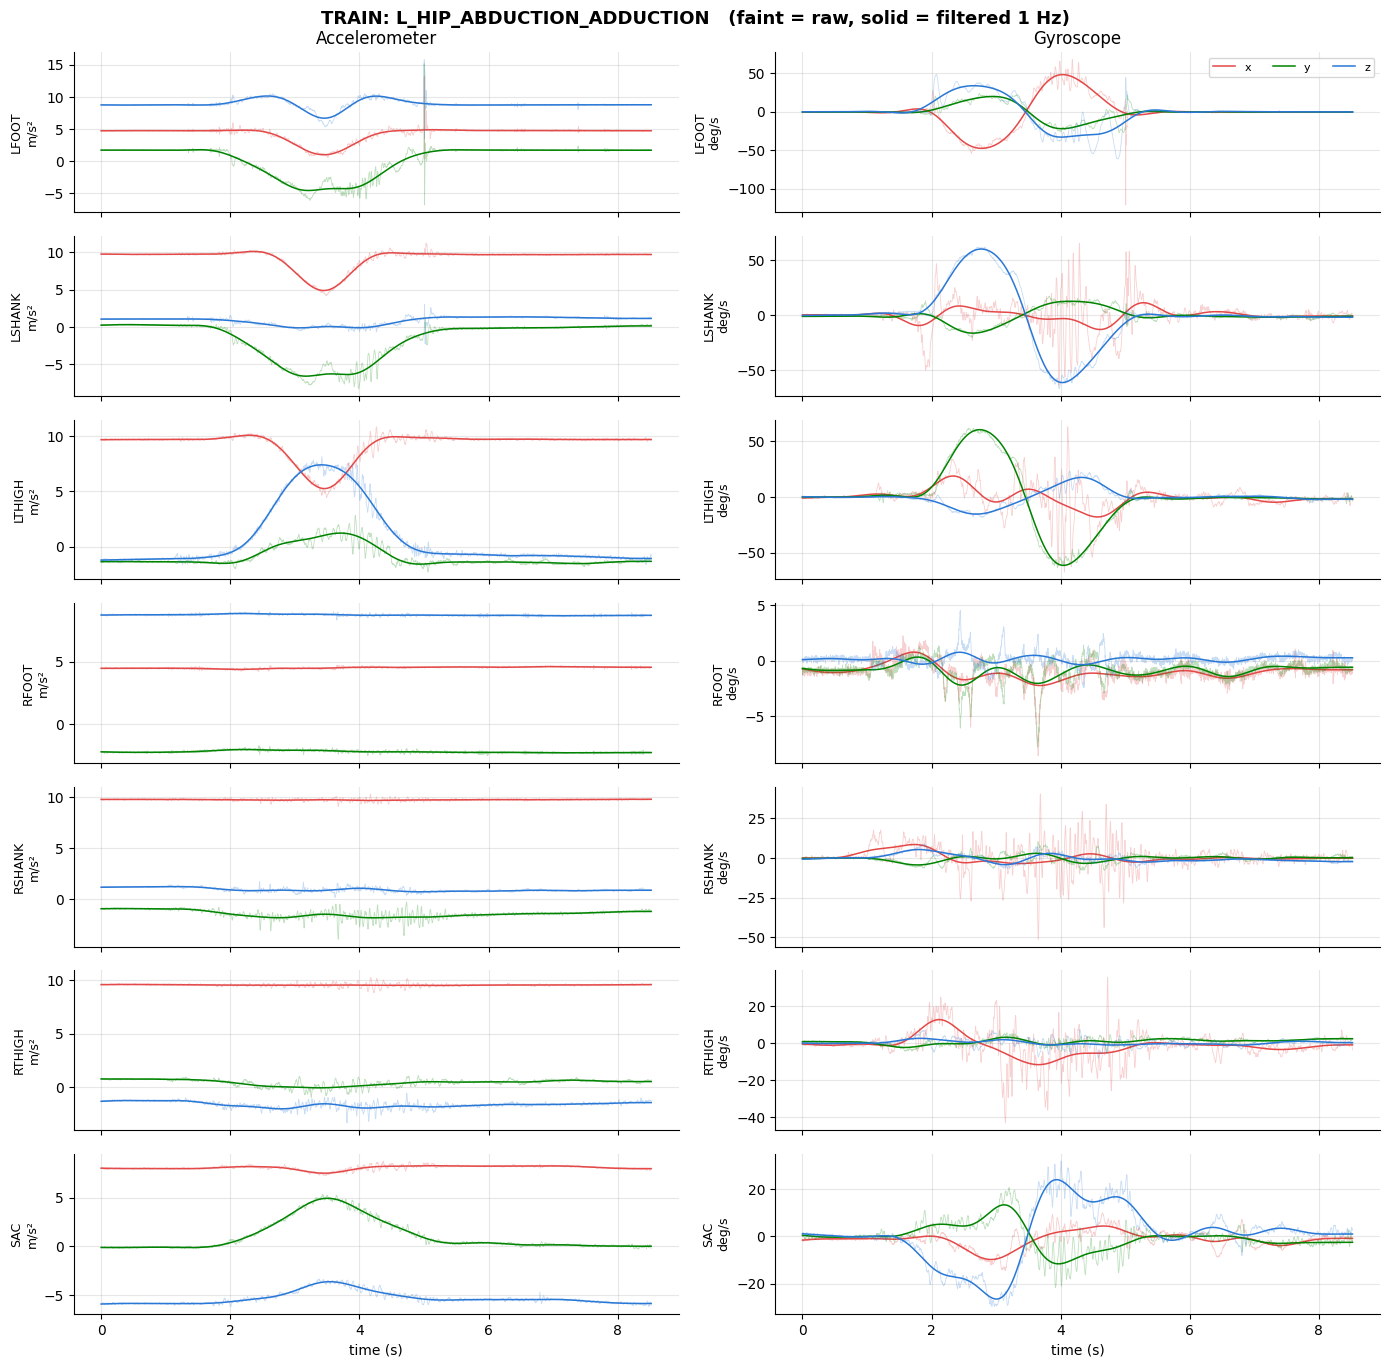

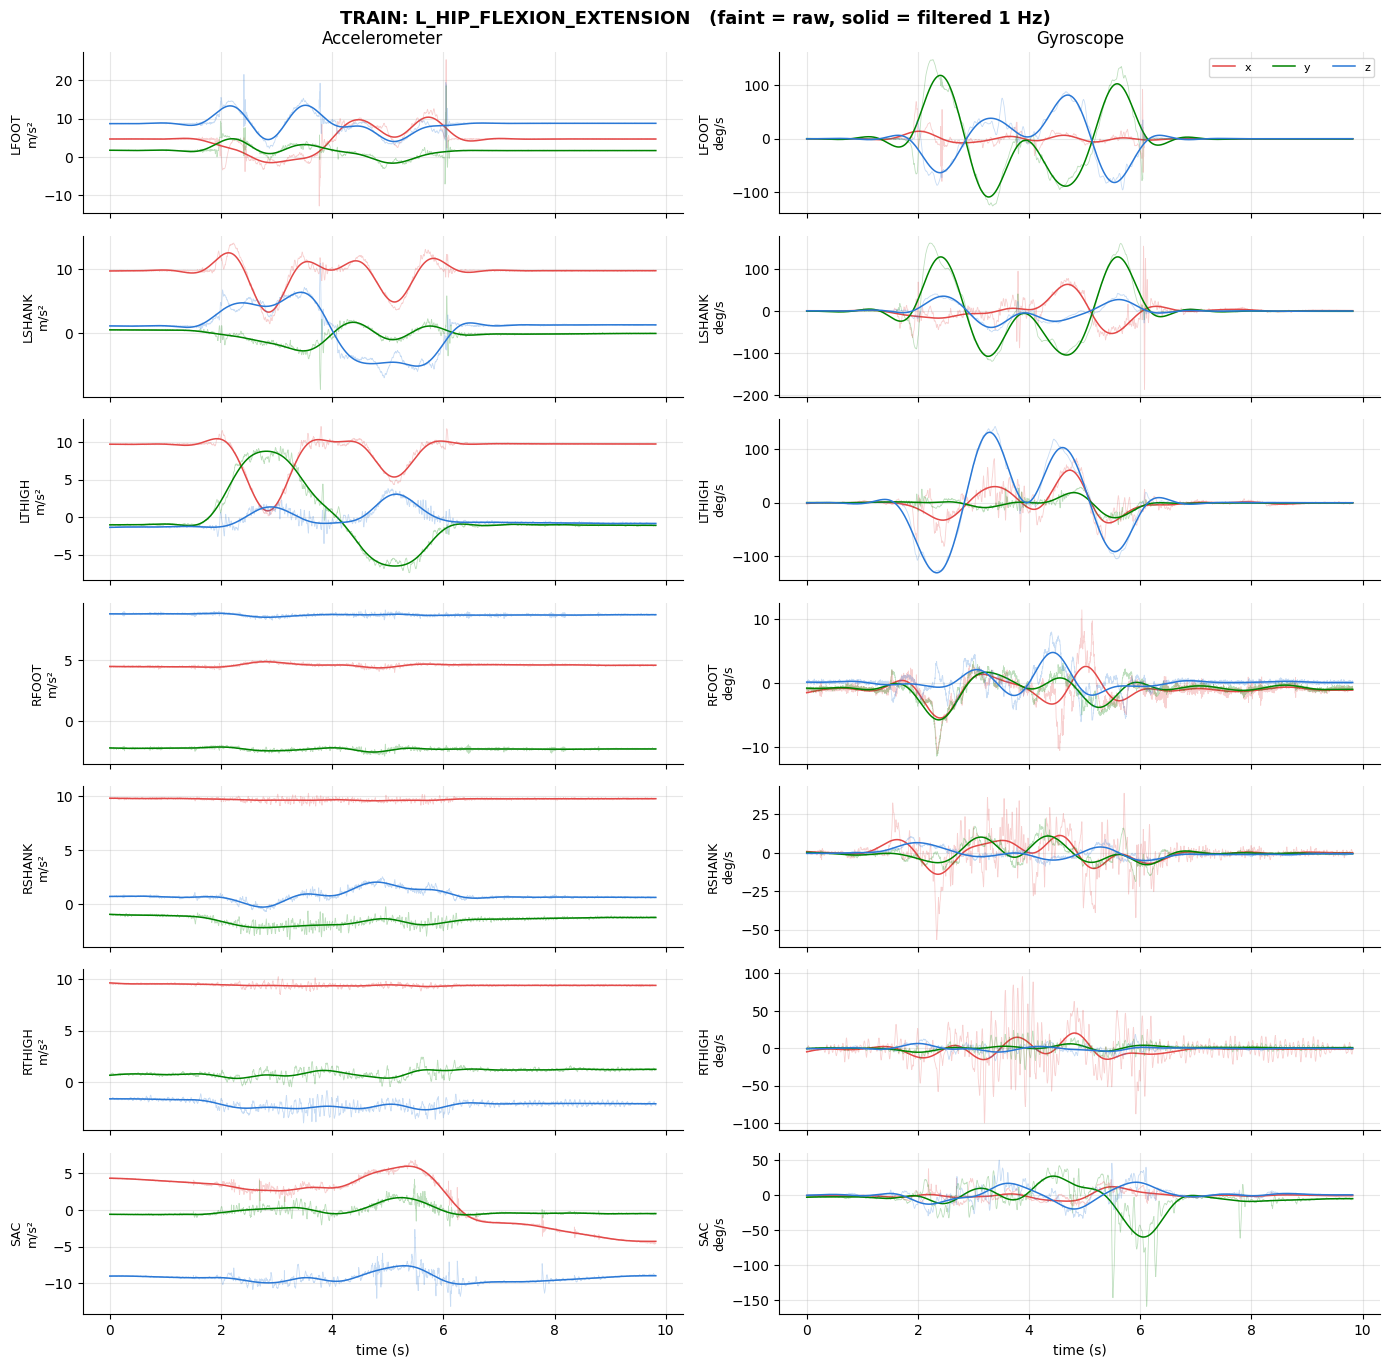

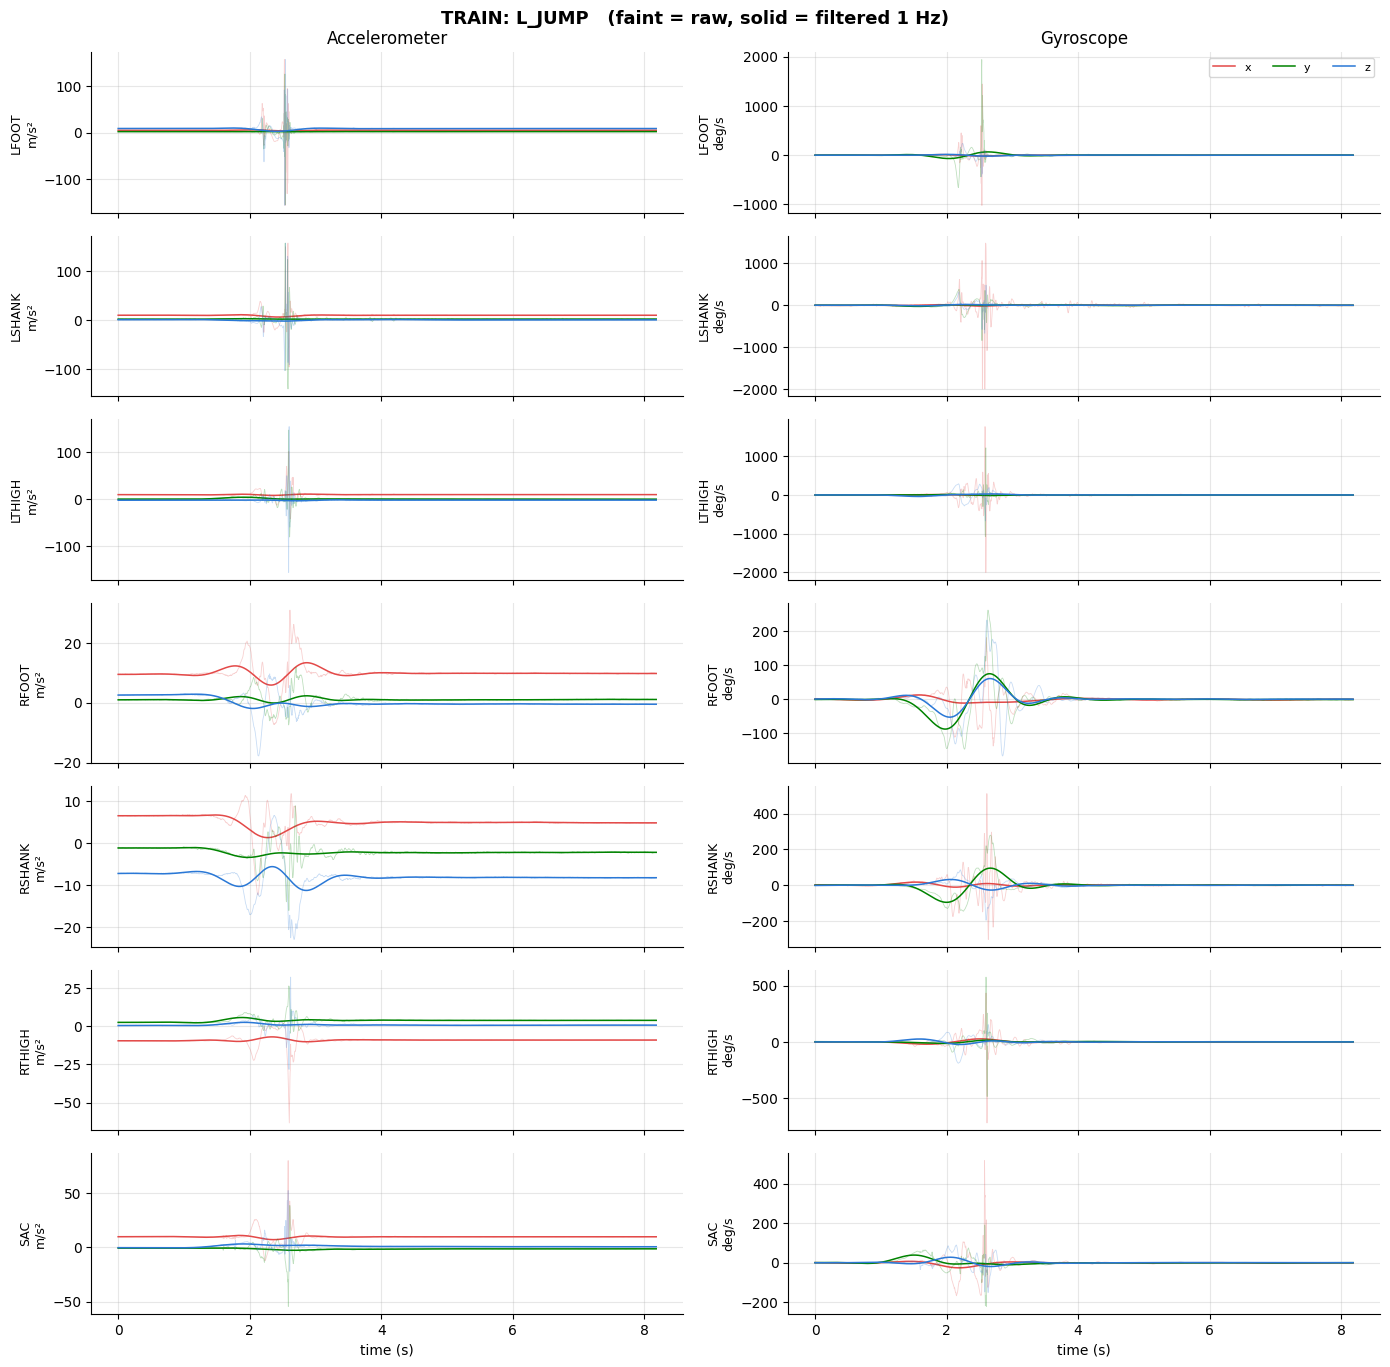

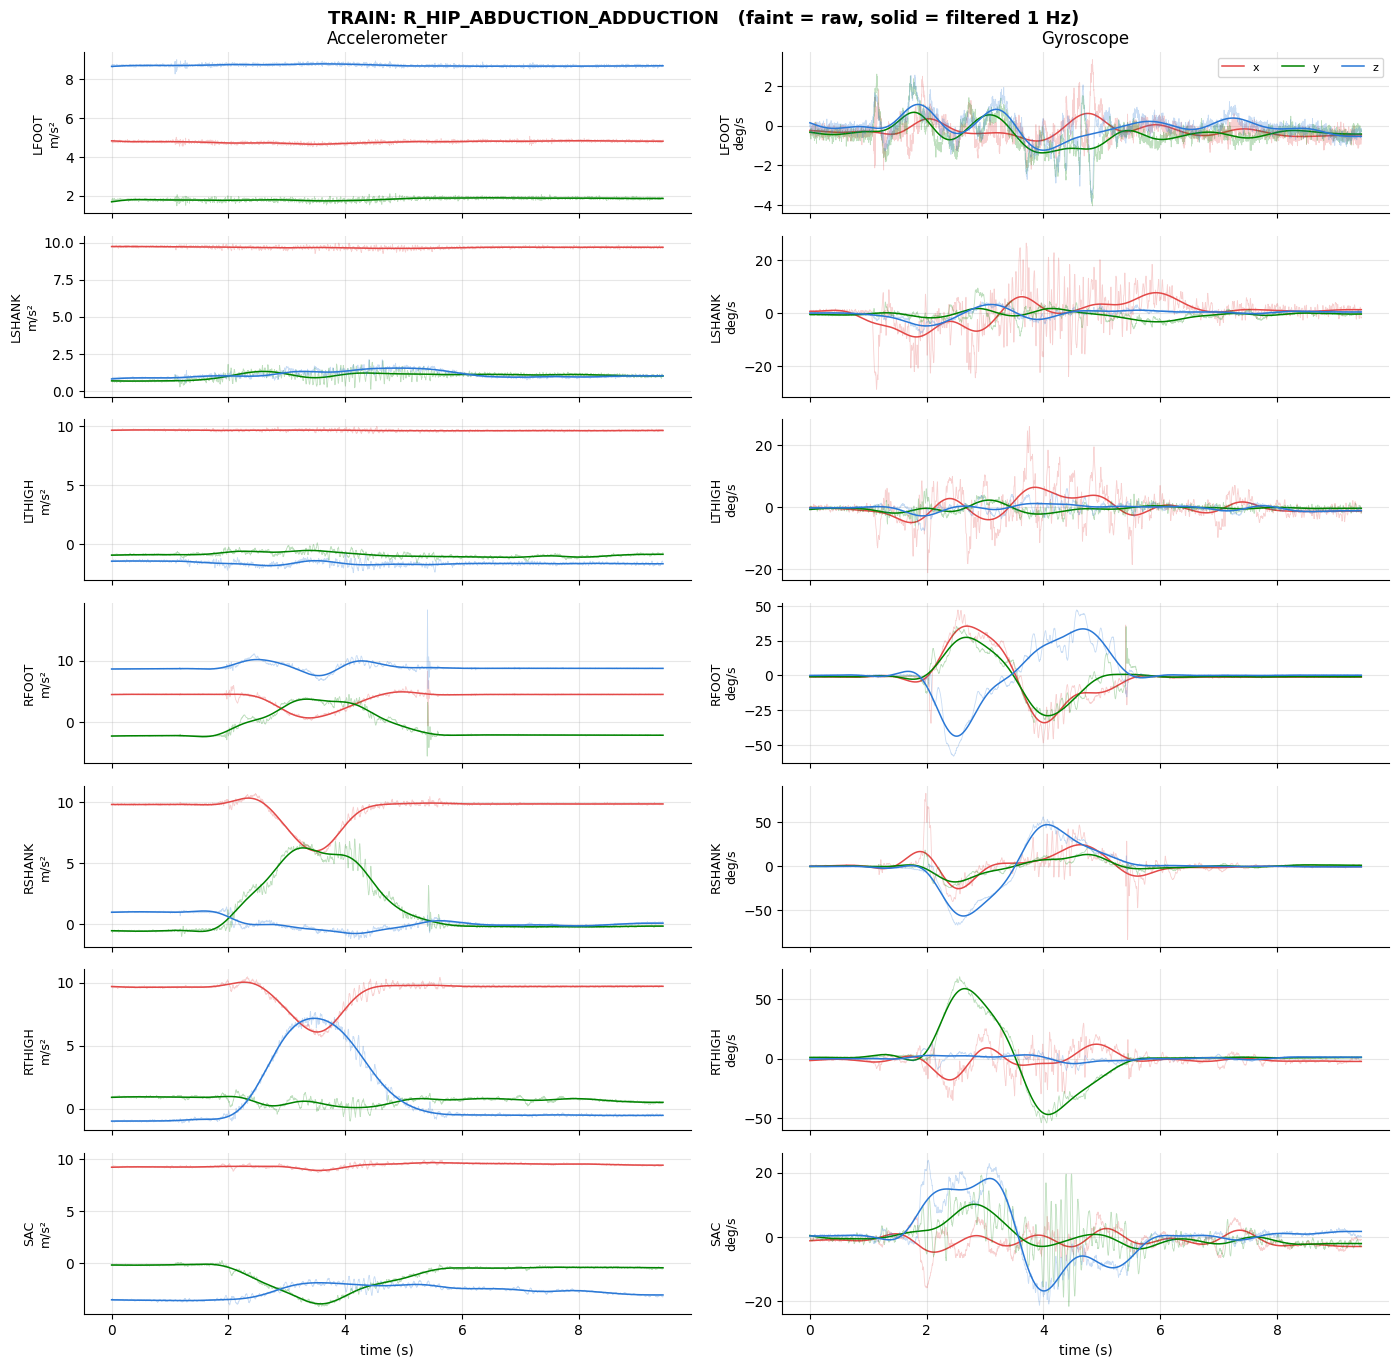

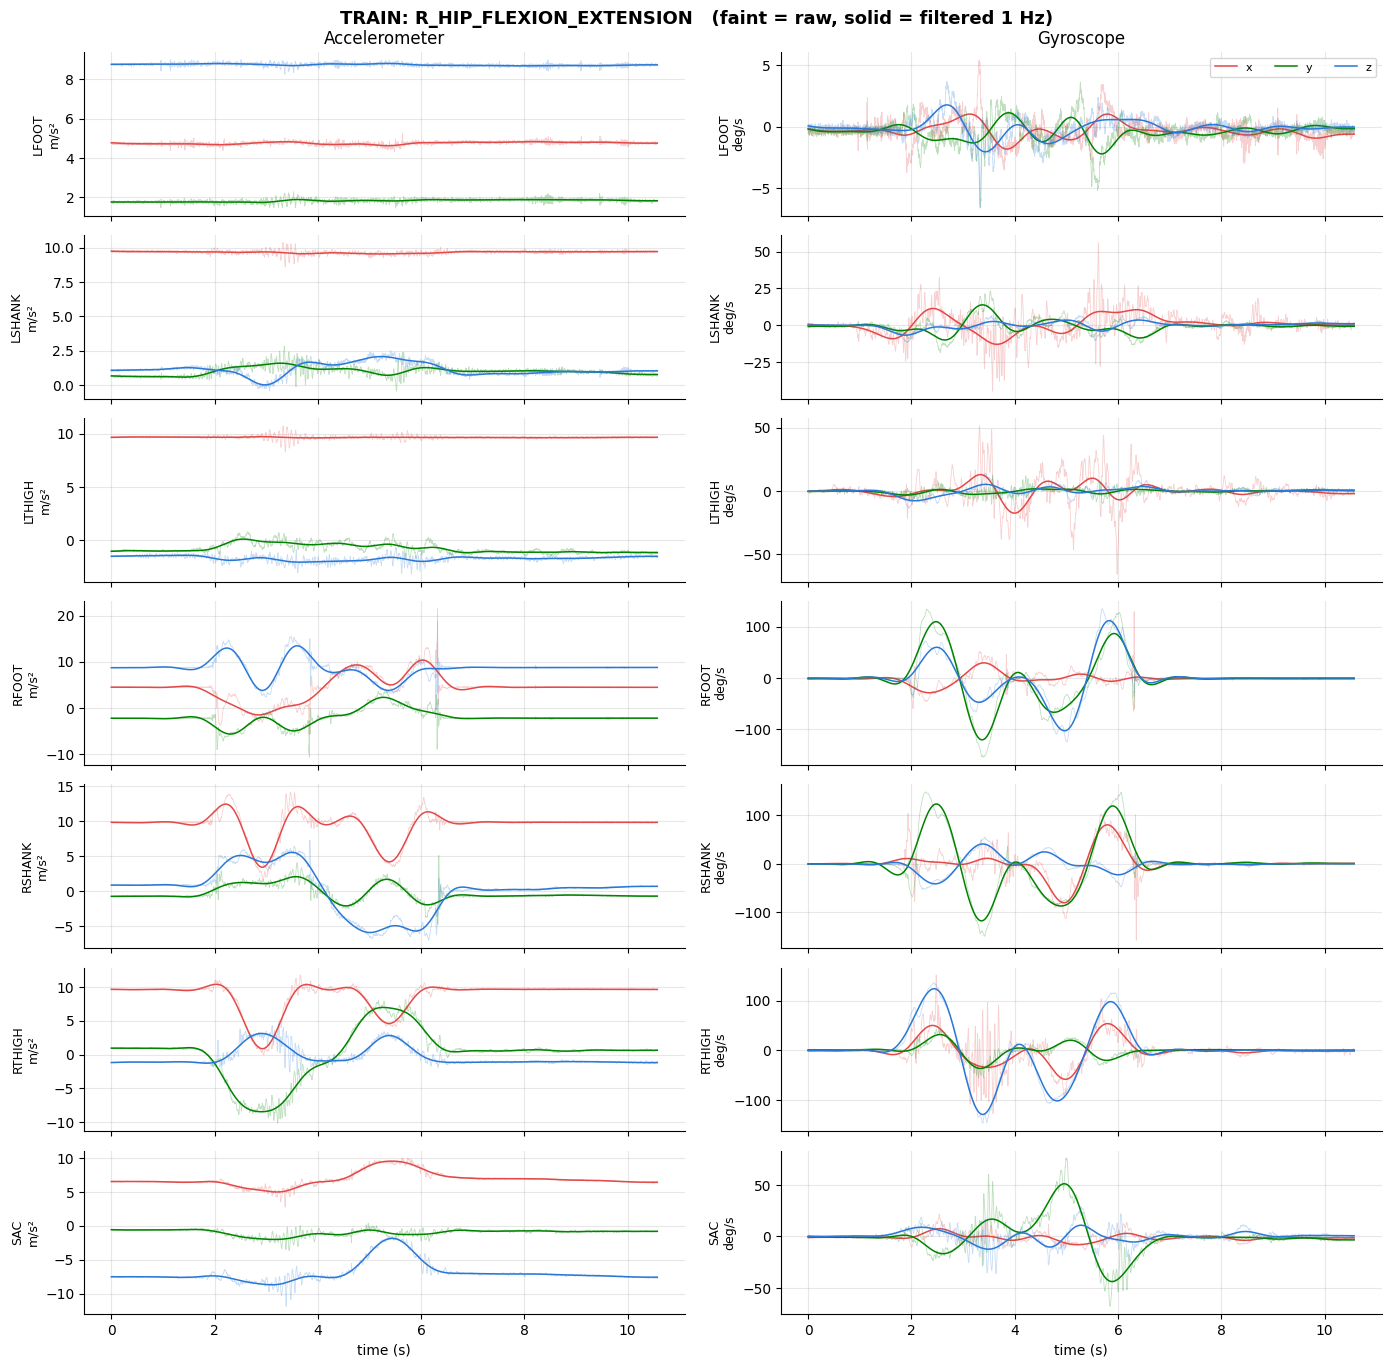

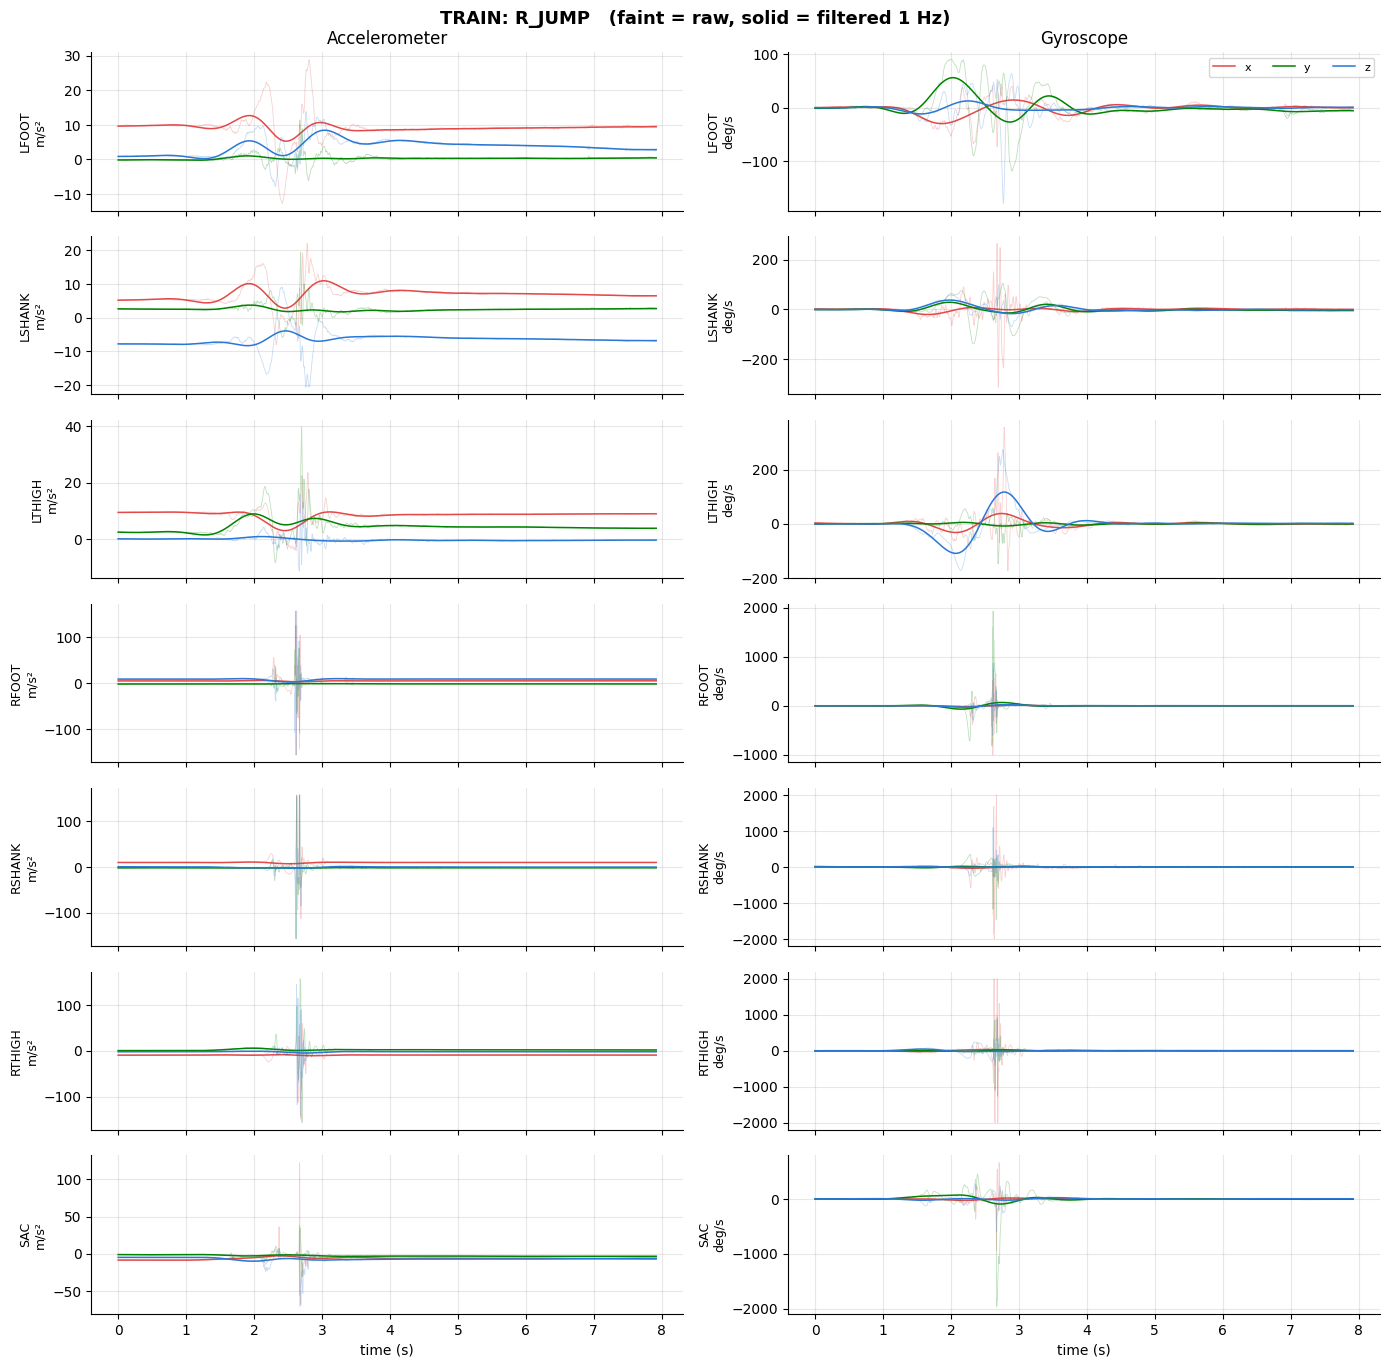

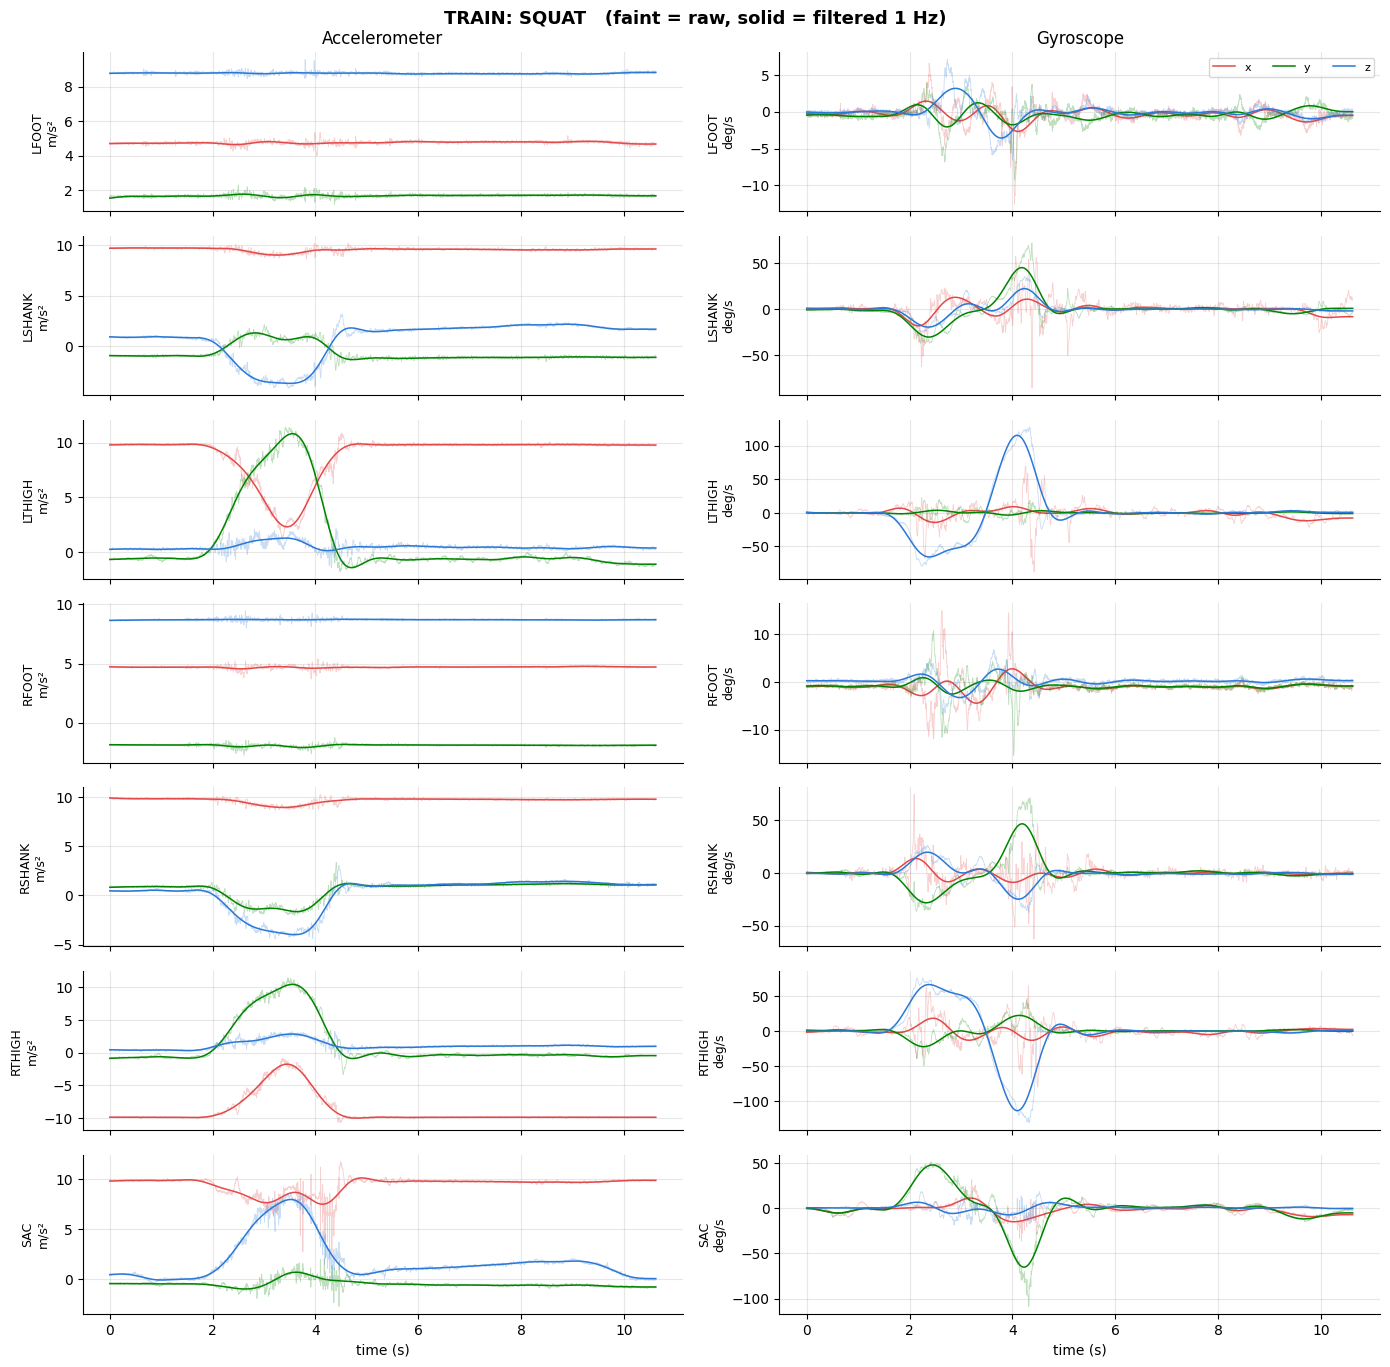

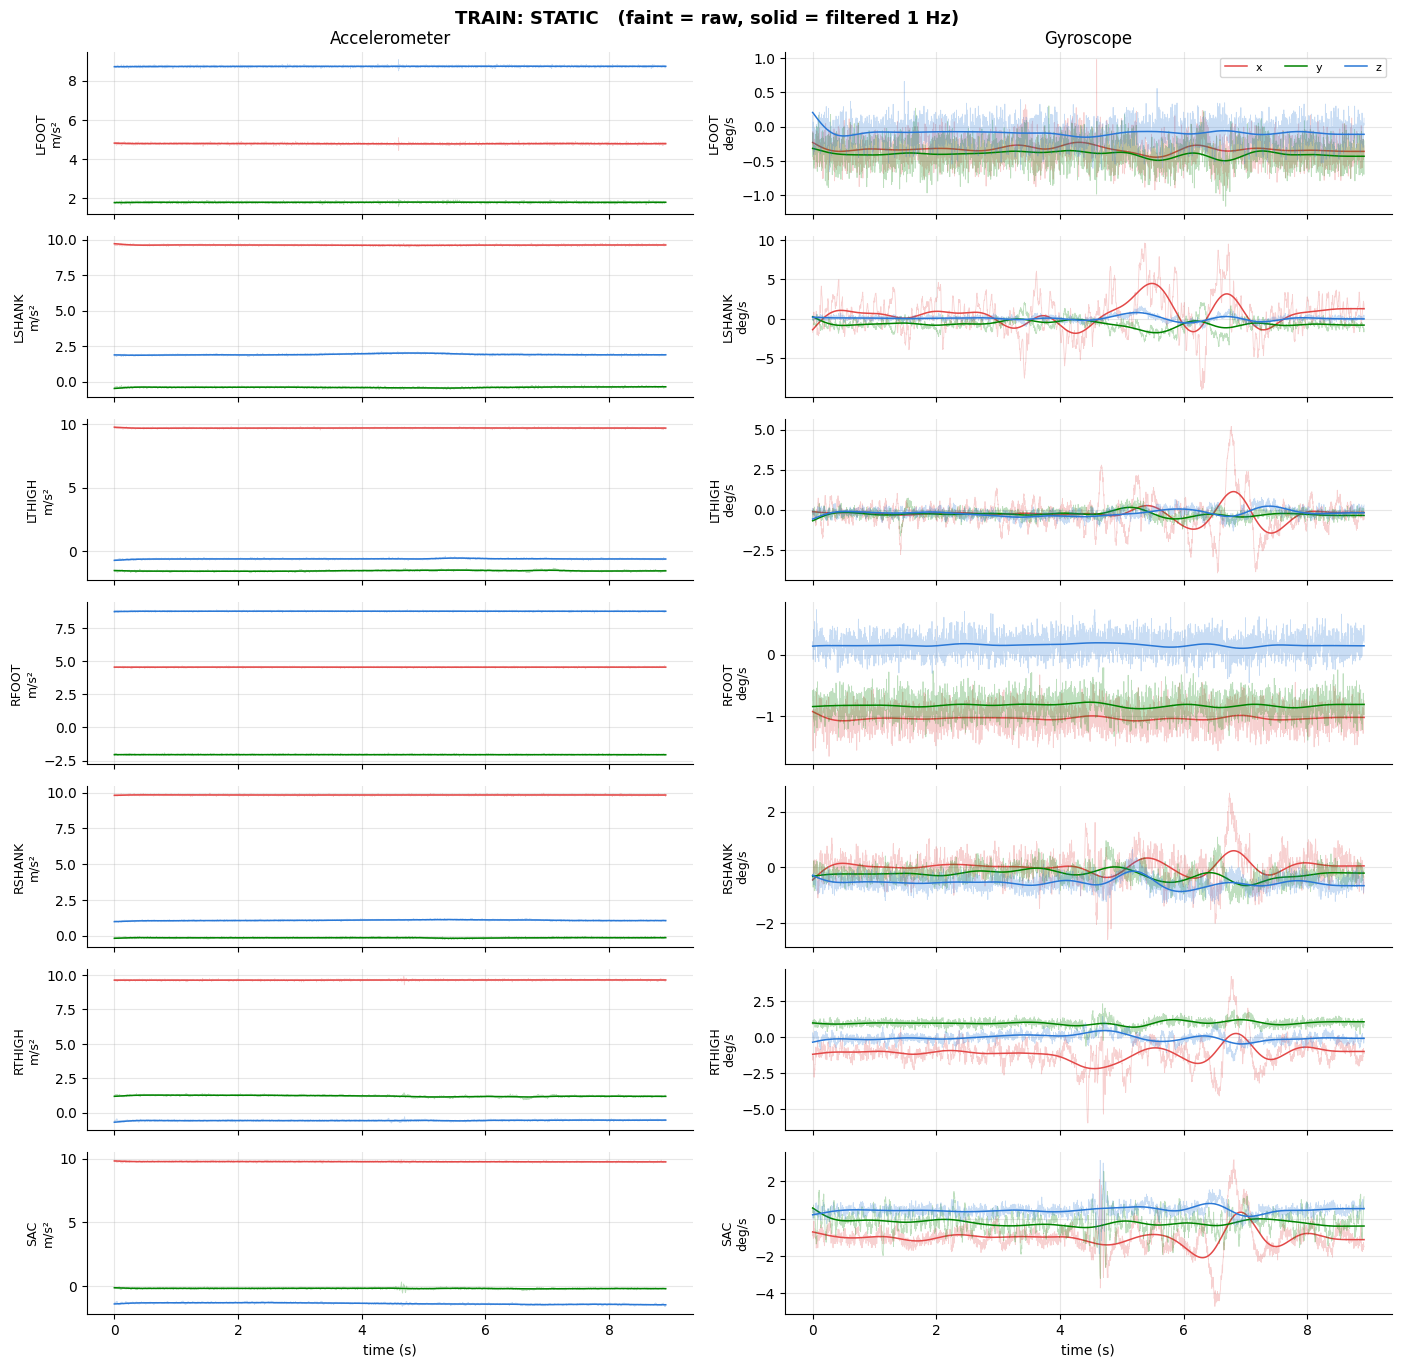

In [ ]:
for recs in SETS.values():
    for rec in recs.values():
        rec['filtered'] = rec['raw'].copy()
        rec['filtered'][CHANNELS] = lowpass(rec['raw'][CHANNELS].values, FILTER_CUTOFF_HZ, FS)


def plot_recording(rec, title, crop=None):
    raw, filt = rec['raw'], rec['filtered']
    fig, axes = plt.subplots(len(SENSORS), 2, figsize=(14, 1.9 * len(SENSORS) + 0.6),
                             sharex=True, squeeze=False)
    for row, sensor in enumerate(SENSORS):
        for col, (kind, unit) in enumerate([('a', 'm/s²'), ('g', 'deg/s')]):
            ax = axes[row, col]
            for color, axis in zip(AXIS_COLORS, 'xyz'):
                name = f'{sensor}_{kind}{axis}'
                ax.plot(raw['time_s'], raw[name], color=color, lw=0.6, alpha=0.25)
                ax.plot(filt['time_s'], filt[name], color=color, lw=1.1, label=axis)
            if crop is not None:
                ax.axvspan(crop['start_s'], crop['end_s'], color='#1baf7a', alpha=0.12)
            ax.set_ylabel(f'{sensor}\n{unit}', fontsize=9)
    axes[0, 0].set_title('Accelerometer'); axes[0, 1].set_title('Gyroscope')
    axes[0, 1].legend(loc='upper right', ncol=3, fontsize=8)
    axes[-1, 0].set_xlabel('time (s)'); axes[-1, 1].set_xlabel('time (s)')
    fig.suptitle(title, fontsize=13, fontweight='bold')
    fig.tight_layout(); plt.show()


SETS_TO_PLOT = ['train']          # ✏️ add 'test' to also plot the test recordings
for set_name in SETS_TO_PLOT:
    for name, rec in SETS[set_name].items():
        plot_recording(rec, f'{set_name.upper()}: {name}   (faint = raw, solid = filtered {FILTER_CUTOFF_HZ} Hz)')

### 1.4 Find where the movement happens and crop

Each recording starts and ends with standing still. To find the moving part:

1. Pick a **reference sensor** and a **reference signal**:
   * `'gyro'`: the **rotation speed** $\sqrt{g_x^2+g_y^2+g_z^2}$. Good for swinging and rotating movements.
   * `'acc'`: how far the **acceleration** moves away from its resting value. Better for movements with little rotation (e.g. a sensor on the pelvis during a jump) or with impacts.
   * Sensor `'auto'` picks the sensor that moves the most in that recording.
2. Smooth that signal with a low-pass Butterworth filter (`ENVELOPE_CUTOFF_HZ`) to get a **movement curve**.
3. The **resting level** is the median of the first second. "Moving" = above `THRESHOLD_FRACTION` of the way from resting level to peak.
4. Keep from the first to the last moving sample, plus `PADDING_S` each side.

If the curve never rises above `STILL_LIMIT`, the recording is a **still** recording (e.g. standing): we keep everything except `EDGE_TRIM_S` at both ends. The same steps are applied to **train and test**.

**Try it:** the explorer below lets you change the reference sensor, signal and threshold for any recording.

> ✏️ **What to change:** when you find better values, put them in ⚙️ Settings: for all movements via `REFERENCE_SENSOR` / `REFERENCE_SIGNAL` / `THRESHOLD_FRACTION`, or for one movement via `REFERENCE_PER_MOVEMENT`, e.g. `{'SQUAT': ('LTHIGH', 'acc')}`. If nothing works, set times by hand in `MANUAL_CROPS`.

In [ ]:
def movement_curve(df, sensor, signal_type, envelope_cutoff_hz=ENVELOPE_CUTOFF_HZ):
    if signal_type == 'gyro':
        size = np.sqrt(df[sensor + '_gx']**2 + df[sensor + '_gy']**2 + df[sensor + '_gz']**2)
    else:   # 'acc': distance of the acceleration from its value at rest (first second)
        acc = df[[sensor + '_ax', sensor + '_ay', sensor + '_az']]
        size = np.sqrt(((acc - acc.iloc[:FS].median())**2).sum(axis=1))
    curve = lowpass(size.values, envelope_cutoff_hz, FS, order=2)
    return np.clip(curve, 0, None)


def find_crop(df, set_name, name, movement, sensor=None, signal=None,
              threshold_fraction=THRESHOLD_FRACTION, envelope_cutoff_hz=ENVELOPE_CUTOFF_HZ):
    # 1) reference sensor and signal (function arguments > per-movement setting > general setting)
    default_sensor, default_signal = REFERENCE_PER_MOVEMENT.get(movement, (REFERENCE_SENSOR, REFERENCE_SIGNAL))
    sensor = sensor or default_sensor
    signal = signal or default_signal
    if sensor == 'auto':
        peaks = {s: movement_curve(df, s, signal, envelope_cutoff_hz).max() for s in SENSORS}
        sensor = max(peaks, key=peaks.get)
    curve = movement_curve(df, sensor, signal, envelope_cutoff_hz)
    t = df['time_s'].values

    # 2) start and end of the movement
    is_still = curve.max() < STILL_LIMIT[signal]
    if (set_name, name) in MANUAL_CROPS:
        start, end = MANUAL_CROPS[(set_name, name)]
    elif not AUTO_CROP:
        start, end = t[0], t[-1]
    elif is_still:
        start, end = t[0] + EDGE_TRIM_S, t[-1] - EDGE_TRIM_S
    else:
        rest_level = np.median(curve[:FS])
        threshold = rest_level + threshold_fraction * (curve.max() - rest_level)
        moving = np.where(curve > threshold)[0]
        start, end = max(t[0], t[moving[0]] - PADDING_S), min(t[-1], t[moving[-1]] + PADDING_S)

    # 3) make sure at least one window fits
    if end - start < WINDOW_S + STEP_S:
        middle = (start + end) / 2
        start = max(t[0], middle - (WINDOW_S + STEP_S) / 2)
        end = min(t[-1], start + WINDOW_S + STEP_S)

    return {'start_s': round(float(start), 2), 'end_s': round(float(end), 2),
            'reference': sensor, 'signal': signal, 'still': bool(is_still)}


def explore_crop(recording, sensor, signal, threshold_fraction, envelope_cutoff_hz):
    set_name, name = recording
    rec = SETS[set_name][name]
    df = rec['filtered']
    c = find_crop(df, set_name, name, rec['movement'], sensor, signal, threshold_fraction, envelope_cutoff_hz)
    curve = movement_curve(df, c['reference'], c['signal'], envelope_cutoff_hz)
    kind = 'g' if c['signal'] == 'gyro' else 'a'
    unit = 'deg/s' if c['signal'] == 'gyro' else 'm/s²'

    fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
    for color, axis in zip(AXIS_COLORS, 'xyz'):
        axes[0].plot(df['time_s'], df[f'{c["reference"]}_{kind}{axis}'], color=color, lw=0.9, label=axis)
    axes[0].set_ylabel(unit); axes[0].legend(loc='upper right', ncol=3, fontsize=8)
    axes[0].set_title(f'{set_name}: {name}   reference = {c["reference"]} ({c["signal"]})')
    axes[1].plot(df['time_s'], curve, color='#2a78d6', lw=2, label='movement curve')
    if not c['still']:
        rest_level = np.median(curve[:FS])
        axes[1].axhline(rest_level + threshold_fraction * (curve.max() - rest_level),
                        color='#e34948', ls='--', lw=1, label='threshold')
    for ax in axes:
        ax.axvspan(c['start_s'], c['end_s'], color='#1baf7a', alpha=0.15)
    axes[1].set_ylabel(unit); axes[1].set_xlabel('time (s)'); axes[1].legend(loc='upper right', fontsize=8)
    fig.tight_layout(); plt.show()
    print(f"Kept {c['start_s']} - {c['end_s']} s" + ('   (still recording)' if c['still'] else ''))
    print(f"To use this for all '{rec['movement']}' recordings, add to Settings:")
    print(f"  REFERENCE_PER_MOVEMENT['{rec['movement']}'] = ('{sensor}', '{signal}')")


recording_options = [(f'{s}: {n}', (s, n)) for s in SETS for n in SETS[s]]
widgets.interact(
    explore_crop,
    recording=widgets.Dropdown(options=recording_options, description='Recording'),
    sensor=widgets.Dropdown(options=['auto'] + SENSORS, value=REFERENCE_SENSOR, description='Ref. sensor'),
    signal=widgets.ToggleButtons(options=['gyro', 'acc'], value=REFERENCE_SIGNAL, description='Ref. signal'),
    threshold_fraction=widgets.FloatSlider(value=THRESHOLD_FRACTION, min=0.02, max=0.5, step=0.01,
                                           description='Threshold', continuous_update=False),
    envelope_cutoff_hz=widgets.FloatSlider(value=ENVELOPE_CUTOFF_HZ, min=0.5, max=10, step=0.5,
                                           description='Smooth Hz', continuous_update=False),
);

interactive(children=(Dropdown(description='Recording', options=(('train: L_HIP_ABDUCTION_ADDUCTION', ('train'…

In [ ]:
REFERENCE_PER_MOVEMENT['L_JUMP'] = ('LTHIGH', 'acc')
REFERENCE_PER_MOVEMENT['R_JUMP'] = ('RTHIGH', 'acc')

Now crop **all** recordings (train and test) with the settings from ⚙️ Settings, and check the result: blue = movement curve of the reference sensor, green = the part we keep.

start_s end_s reference signal  still
set   recording                                                      
train L_HIP_ABDUCTION_ADDUCTION    1.65  5.26    LTHIGH   gyro  False
      L_HIP_FLEXION_EXTENSION      1.26  6.38    LSHANK   gyro  False
      L_JUMP                       1.01  3.79    LTHIGH    acc  False
      R_HIP_ABDUCTION_ADDUCTION    1.37  6.16    RSHANK   gyro  False
      R_HIP_FLEXION_EXTENSION      1.32   6.7    RSHANK   gyro  False
      R_JUMP                       1.08  7.92    RTHIGH    acc  False
      SQUAT                        1.51  4.92    RTHIGH   gyro  False
      STATIC                        1.0  7.92    LSHANK   gyro   True
test  L_HIP_ABDUCTION_ADDUCTION    1.65  5.26    LTHIGH   gyro  False
      L_HIP_FLEXION_EXTENSION      1.26  6.38    LSHANK   gyro  False
      L_JUMP                       1.01  3.79    LTHIGH    acc  False
      R_HIP_ABDUCTION_ADDUCTION    1.37  6.16    RSHANK   gyro  False
      R_HIP_FLEXION_EXTENSION      1.32   6.7    RSHANK   gyro  False
      R_JUMP                       1.08  7.92    RTHIGH    acc  False
      SQUAT                        1.51  4.92    RTHIGH   gyro  False
      STATIC                        1.0  7.92    LSHANK   gyro   True

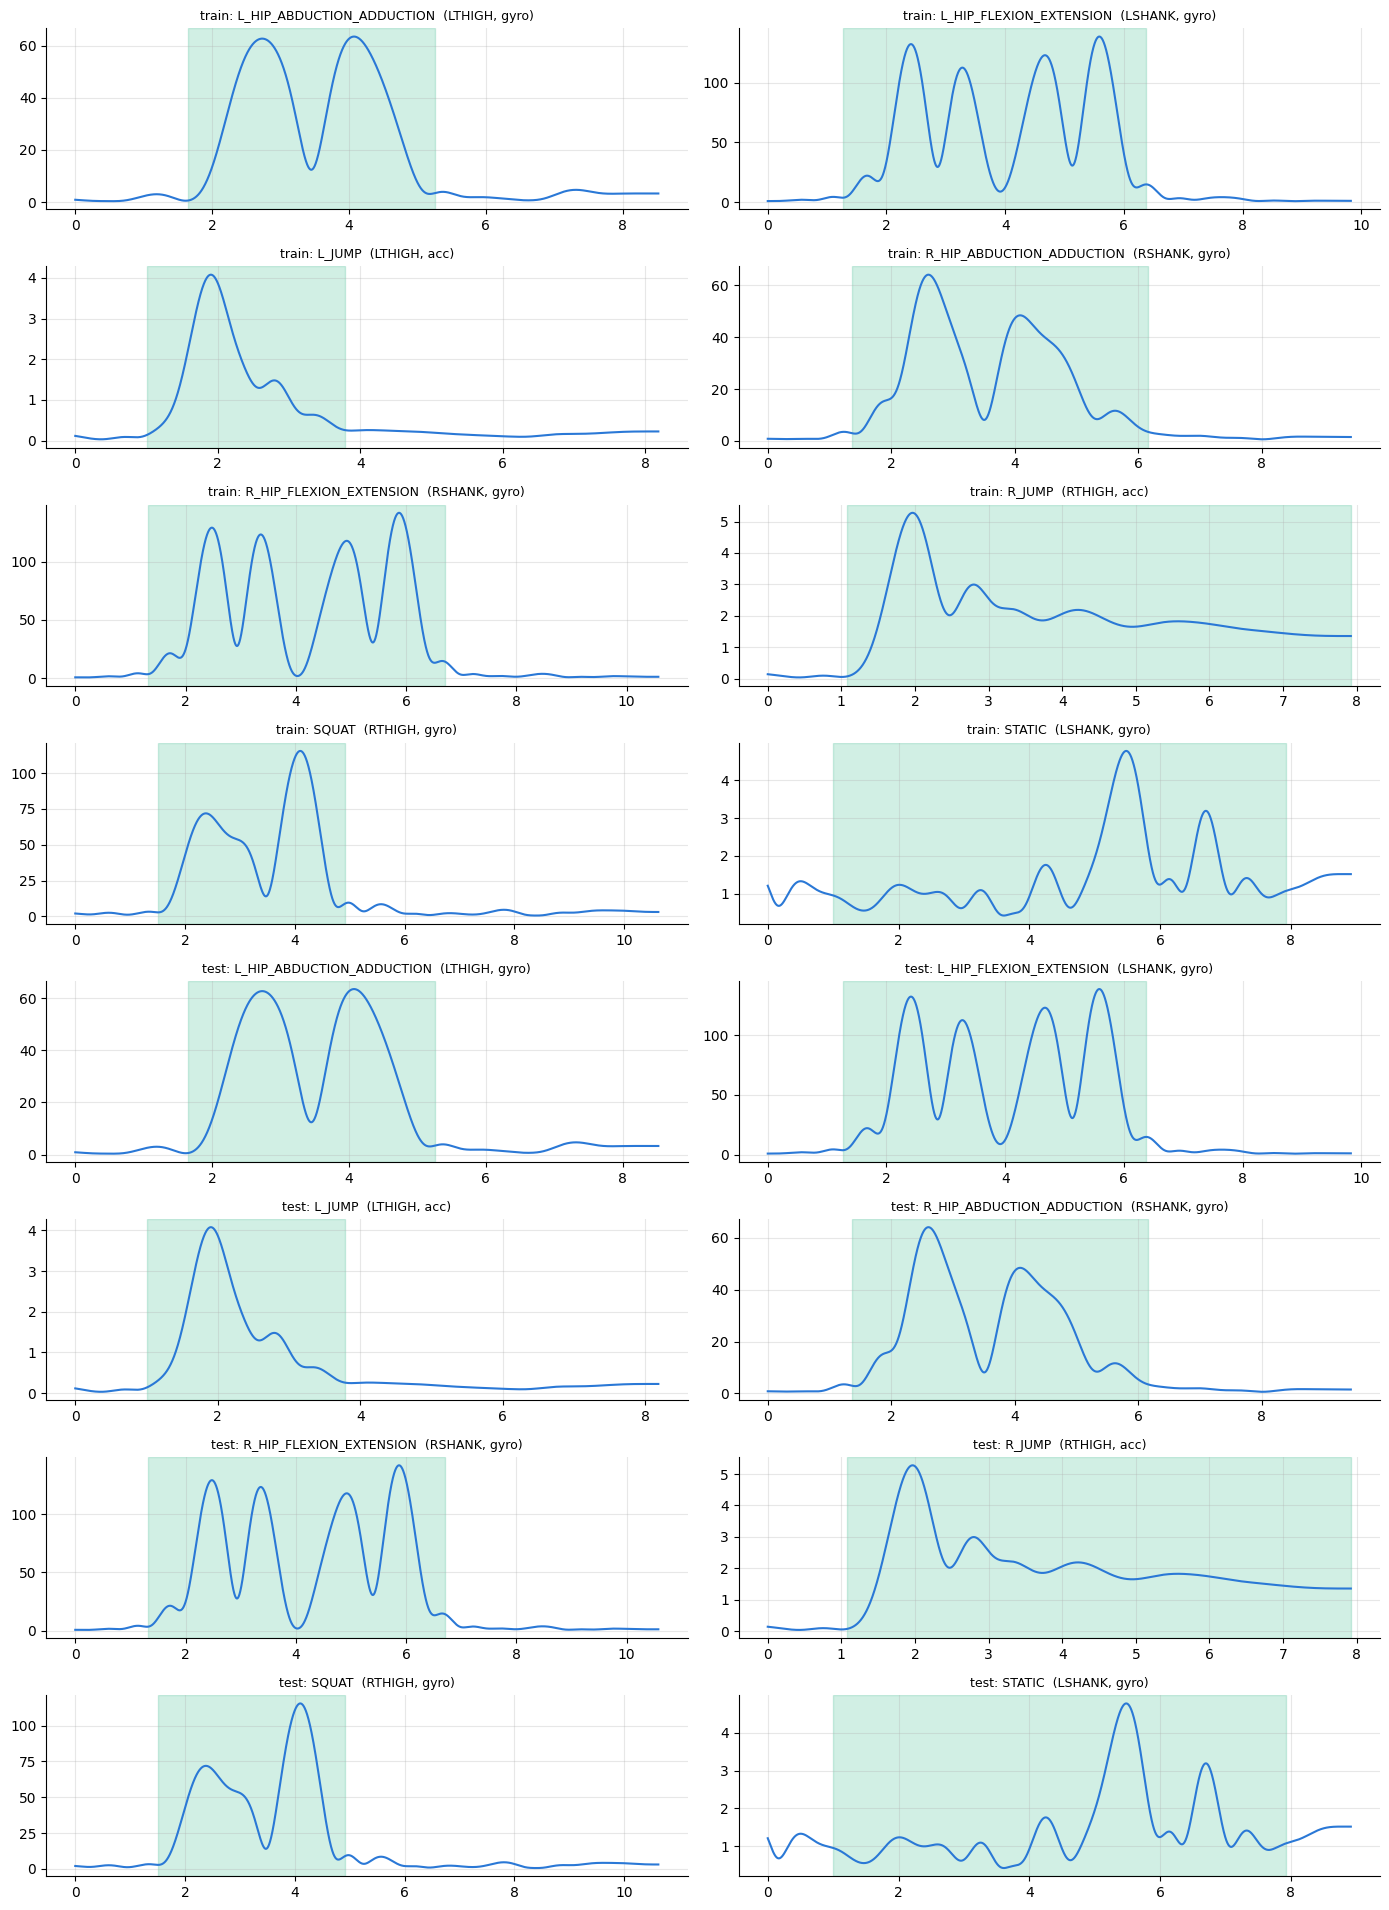

In [ ]:
for set_name, recs in SETS.items():
    for name, rec in recs.items():
        rec['crop'] = find_crop(rec['filtered'], set_name, name, rec['movement'])

crop_table = pd.DataFrame({(s, n): r['crop'] for s, recs in SETS.items() for n, r in recs.items()}).T
crop_table.index.names = ['set', 'recording']
display(crop_table)

all_recs = [(s, n, r) for s, recs in SETS.items() for n, r in recs.items()]
n_rows = int(np.ceil(len(all_recs) / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(14, 2.4 * n_rows), squeeze=False)
for ax, (set_name, name, rec) in zip(axes.ravel(), all_recs):
    c = rec['crop']
    df = rec['filtered']
    ax.plot(df['time_s'], movement_curve(df, c['reference'], c['signal']), color='#2a78d6', lw=1.5)
    ax.axvspan(c['start_s'], c['end_s'], color='#1baf7a', alpha=0.2)
    ax.set_title(f'{set_name}: {name}  ({c["reference"]}, {c["signal"]})', fontsize=9)
for ax in axes.ravel()[len(all_recs):]:
    ax.axis('off')
fig.tight_layout(); plt.show()

### 1.5 Downsample

At 400 Hz every second has 400 samples, more than we need after removing everything above `FILTER_CUTOFF_HZ`. We keep every *k*-th sample to get `TARGET_FS` (100 Hz by default). This makes the windows smaller and the CNN faster, without losing information, as long as `TARGET_FS` is more than twice the filter cut-off.

We keep two versions of every recording: the **cropped** movement (for training and testing) and the **full** recording (for the quiet periods and the timeline plots in Part 4).

> ✏️ **What to change:** usually nothing. `TARGET_FS` must divide your sampling rate.

In [ ]:
DS = max(1, round(FS / TARGET_FS))         # keep every DS-th sample
FS_MODEL = FS / DS
if FILTER_CUTOFF_HZ >= FS_MODEL / 2:
    print(f'⚠️ FILTER_CUTOFF_HZ ({FILTER_CUTOFF_HZ}) should be below {FS_MODEL / 2} Hz for this TARGET_FS.')

for recs in SETS.values():
    for rec in recs.values():
        c, df = rec['crop'], rec['filtered']
        keep = (df['time_s'] >= c['start_s']) & (df['time_s'] <= c['end_s'])
        rec['cropped'] = df[keep].iloc[::DS].reset_index(drop=True)
        rec['full'] = df.iloc[::DS].reset_index(drop=True)

print(f'Downsampled from {FS} Hz to {FS_MODEL:g} Hz')
pd.DataFrame({(s, n): {'cropped (s)': round(len(r['cropped']) / FS_MODEL, 2),
                       'samples': len(r['cropped'])} for s, recs in SETS.items() for n, r in recs.items()}).T

Downsampled from 400 Hz to 100 Hz


cropped (s)  samples
train L_HIP_ABDUCTION_ADDUCTION         3.62    362.0
      L_HIP_FLEXION_EXTENSION           5.13    513.0
      L_JUMP                            2.79    279.0
      R_HIP_ABDUCTION_ADDUCTION         4.80    480.0
      R_HIP_FLEXION_EXTENSION           5.39    539.0
      R_JUMP                            6.85    685.0
      SQUAT                             3.42    342.0
      STATIC                            6.93    693.0
test  L_HIP_ABDUCTION_ADDUCTION         3.62    362.0
      L_HIP_FLEXION_EXTENSION           5.13    513.0
      L_JUMP                            2.79    279.0
      R_HIP_ABDUCTION_ADDUCTION         4.80    480.0
      R_HIP_FLEXION_EXTENSION           5.39    539.0
      R_JUMP                            6.85    685.0
      SQUAT                             3.42    342.0
      STATIC                            6.93    693.0

---
## Part 2: Data pre-processing



### 2.1 Sliding windows: using a time duration, not single samples

A single sample is one instant: a thigh rotating at 100 deg/s could be a squat, a kick or a jump. A movement only becomes recognisable **over time**. So we cut each recording into **windows** of `WINDOW_S` seconds, and the model gets one whole window at a time.

The window **slides** forward by `STEP_S` each step, so consecutive windows overlap. That gives many training examples from one recording and lets the model detect a movement at any moment in a continuous recording.

The plot below shows this on a training recording: the first windows drawn as bars underneath the signal.

> ✏️ **What to change:** `WINDOW_S` should be about the length of your **shortest movement**, so one window holds most of a movement. `STEP_S` controls overlap: smaller = more (but more similar) windows.

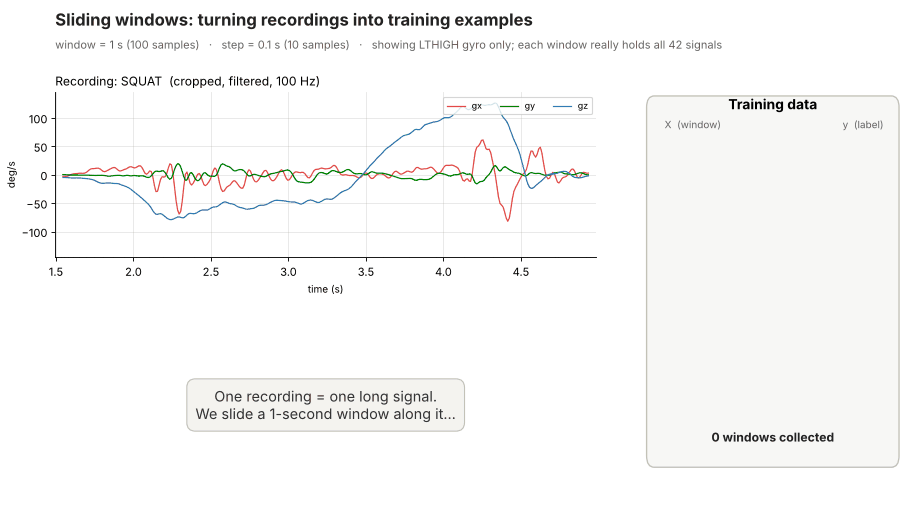

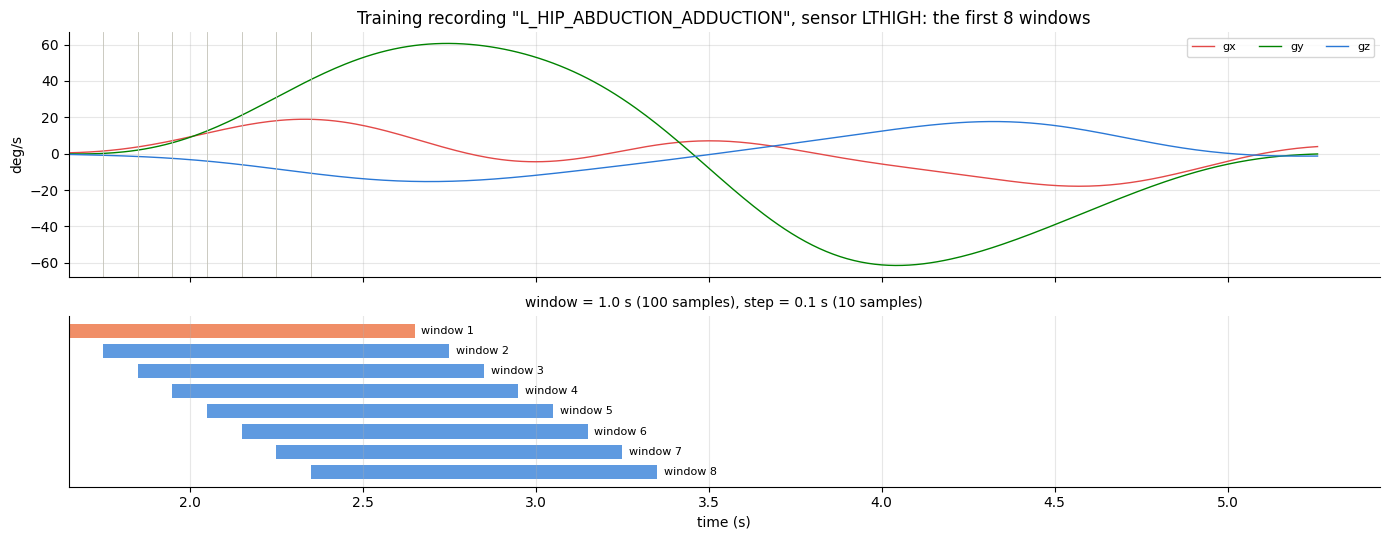

In [ ]:
WIN = int(round(WINDOW_S * FS_MODEL))     # samples per window
STEP = int(round(STEP_S * FS_MODEL))      # samples per step


def make_windows(df):
    values, times = df[CHANNELS].values, df['time_s'].values
    starts = list(range(0, len(df) - WIN + 1, STEP))
    X = np.array([values[s:s + WIN] for s in starts]).reshape(len(starts), WIN, len(CHANNELS))
    t_centre = np.array([times[s + WIN // 2] for s in starts])
    return X, t_centre


# Pick a training recording with movement for the demo plots
demo_name = next(n for n, r in train_recs.items() if not r['crop']['still'])
demo = train_recs[demo_name]['cropped']
demo_sensor = train_recs[demo_name]['crop']['reference']
n_show = 8

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True, gridspec_kw={'height_ratios': [2, 1.4]})
for color, axis in zip(AXIS_COLORS, 'xyz'):
    ax1.plot(demo['time_s'], demo[f'{demo_sensor}_g{axis}'], color=color, lw=1, label=f'g{axis}')
ax1.set_ylabel('deg/s'); ax1.legend(loc='upper right', ncol=3, fontsize=8)
ax1.set_title(f'Training recording "{demo_name}", sensor {demo_sensor}: the first {n_show} windows')
t0 = demo['time_s'].iloc[0]
for k in range(n_show):
    start = t0 + k * STEP / FS_MODEL
    ax2.barh(k, WINDOW_S, left=start, height=0.7, color='#2a78d6' if k else '#eb6834', alpha=0.75)
    ax2.text(start + WINDOW_S + 0.02, k, f'window {k + 1}', va='center', fontsize=8)
    ax1.axvline(start, color='#c3c2b7', lw=0.6)
ax2.invert_yaxis(); ax2.set_yticks([])
ax2.set_xlabel('time (s)')
ax2.set_title(f'window = {WINDOW_S} s ({WIN} samples), step = {STEP_S} s ({STEP} samples)', fontsize=10)
fig.tight_layout(); plt.show()

### 2.2 Build the training and test sets

* **Training windows** come from the cropped movement of every **training** recording, labelled with its movement name.
* **Extra rest examples:** the quiet periods before and after each movement in the **training** recordings are added with the rest label (`REST_LABEL`). Otherwise the model only knows "standing still" from a single recording.
* **Test windows** come from the cropped movement of every **test** recording.

Both sets went through exactly the same cleaning: filter → crop → downsample.

> ✏️ **What to change:** `REST_LABEL` and `REST_MARGIN_S` in ⚙️ Settings.

In [ ]:
still_movements = sorted({r['movement'] for r in train_recs.values() if r['crop']['still']})
if REST_LABEL == 'auto':
    rest_label = still_movements[0] if still_movements else 'REST'
else:
    rest_label = REST_LABEL
print('Still recordings:', still_movements, '| rest label:', rest_label)


def quiet_parts(rec):
    # Quiet periods before and after the movement (at least one window long)
    full, c = rec['full'], rec['crop']
    before = full[full['time_s'] < c['start_s'] - REST_MARGIN_S]
    after = full[full['time_s'] > c['end_s'] + REST_MARGIN_S]
    return [part for part in (before, after) if len(part) >= WIN]


def build_set(recs, add_rest):
    X_parts, labels = [], []
    for rec in recs.values():
        X, _ = make_windows(rec['cropped'])
        X_parts.append(X); labels += [rec['movement']] * len(X)
        if add_rest and rest_label is not None and not rec['crop']['still']:
            for quiet in quiet_parts(rec):
                Xq, _ = make_windows(quiet)
                X_parts.append(Xq); labels += [rest_label] * len(Xq)
    return np.concatenate(X_parts), np.array(labels)


X_train, y_train = build_set(train_recs, add_rest=True)
X_test, y_test = build_set(test_recs, add_rest=False)
LABELS = sorted(set(y_train))
y_train_id = np.array([LABELS.index(l) for l in y_train])
y_test_id = np.array([LABELS.index(l) for l in y_test])

print(f'Window shape: {WIN} time steps × {len(CHANNELS)} signals')
print(f'Training windows: {len(X_train)},  test windows: {len(X_test)}')
pd.DataFrame({'train windows': pd.Series(y_train).value_counts(),
              'test windows': pd.Series(y_test).value_counts()}).fillna(0).astype(int)

Still recordings: ['STATIC'] | rest label: STATIC
Window shape: 100 time steps × 42 signals
Training windows: 469,  test windows: 314


,train windows,test windows
STATIC,215,60
R_JUMP,59,59
R_HIP_FLEXION_EXTENSION,44,44
L_HIP_FLEXION_EXTENSION,42,42
R_HIP_ABDUCTION_ADDUCTION,39,39
L_HIP_ABDUCTION_ADDUCTION,27,27
SQUAT,25,25
L_JUMP,18,18


### 2.3 Normalise

Accelerations (nearly 10 m/s²) and rotation speeds (nearly hundreds of deg/s) have very different magnitudes. Neural networks learn best when all inputs have a similar range, so we scale each signal to **mean 0, standard deviation 1**.

The mean and standard deviation are computed **from the training data only**, and the same values are applied to the test data (the test data must not influence training in any way).

In [ ]:
CH_MEAN = X_train.mean(axis=(0, 1))
CH_STD = X_train.std(axis=(0, 1)) + 1e-8

def normalise(X):
    return (X - CH_MEAN) / CH_STD

Xn_train = normalise(X_train)
Xn_test = normalise(X_test)
print('Normalised training data: mean', Xn_train.mean().round(3), ', std', Xn_train.std().round(3))

Normalised training data: mean -0.0 , std 1.0


---
## Part 3: Model training

We train two models and compare them:

| | Random Forest (baseline) | 1D CNN (main model) |
|---|---|---|
| Input | a few **statistics** per signal (mean, std, min, max) | the **whole window**, time step by time step |
| Keeps the order of events? | ❌ "the thigh rotated" | ✅ "the thigh rotated forwards, *then* back" |
| Needs | little data, no tuning | more data (we use augmentation), a few settings |



### 3.1 Baseline: Random Forest on window statistics

Each window is squeezed into a few numbers per signal using `FEATURE_FUNCTIONS`. A Random Forest (many decision trees voting) learns from those numbers. It is quick and a good reference point: the CNN should do at least as well.

> ✏️ **What to change:** add statistics to `FEATURE_FUNCTIONS` in ⚙️ Settings, e.g. `'range': np.ptp`.

Random Forest trained on 168 statistics per window


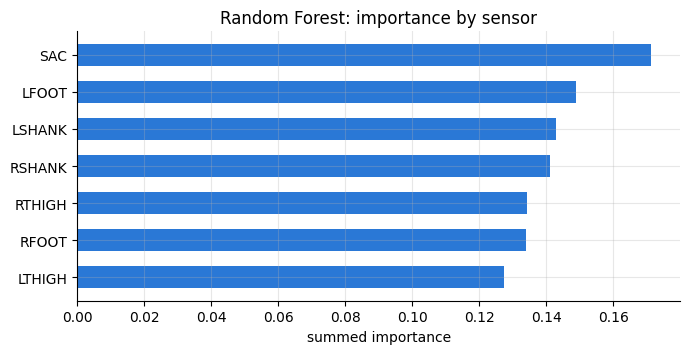

In [ ]:
def window_statistics(X):
    # (windows, time, signals) -> (windows, signals × statistics)
    return np.concatenate([func(X, axis=1) for func in FEATURE_FUNCTIONS.values()], axis=1)

FEATURE_NAMES = [f'{ch}_{stat}' for stat in FEATURE_FUNCTIONS for ch in CHANNELS]
F_train, F_test = window_statistics(X_train), window_statistics(X_test)

rf_model = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_SEED)
rf_model.fit(F_train, y_train)
print(f'Random Forest trained on {F_train.shape[1]} statistics per window')

# Which sensors does it rely on?
importance = pd.Series(rf_model.feature_importances_, index=FEATURE_NAMES)
sensor_of_feature = [name.rsplit('_', 2)[0] for name in FEATURE_NAMES]   # 'LTHIGH_ax_mean' -> 'LTHIGH'
by_sensor = importance.groupby(sensor_of_feature).sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 0.35 * len(SENSORS) + 1.2))
ax.barh(by_sensor.index, by_sensor.values, color='#2a78d6', height=0.6)
ax.set_title('Random Forest: importance by sensor'); ax.set_xlabel('summed importance')
fig.tight_layout(); plt.show()

### 3.2 Main model: a 1D Convolutional Neural Network (CNN)

A **1D CNN** slides small **filters** (e.g. 7 time steps long, across all signals) along the window. Each filter learns to respond to a short pattern, such as "thigh rotates forward while the foot accelerates". Deeper layers combine these into longer patterns. Finally, **global average pooling** summarises where the patterns occurred, and the last layer outputs a probability for each movement.

```
window (100 × 42) → Conv1D(32) → MaxPool → Conv1D(64) → MaxPool → Conv1D(64) → GlobalAvgPool → Dropout → Dense(movements)
```

**Data augmentation.** We have very few recordings, and a CNN can simply memorise them. To teach it that a movement may be done slightly differently, we add `AUGMENT_COPIES` changed copies of every training window: a bit of **noise**, slightly **bigger/smaller**, slightly **faster/slower**, slightly **shifted** in time. The plot shows one signal of one window and three augmented versions.

> ✏️ **What to change:** the augmentation and training settings in ⚙️ Settings; the layers in `build_cnn()` (e.g. more filters, another `Conv1D` layer, a different `kernel_size`).

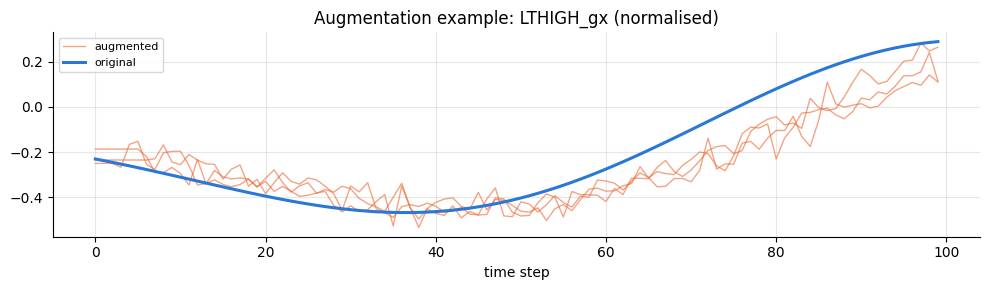

Training windows after augmentation: 2814


In [ ]:
rng = np.random.default_rng(RANDOM_SEED)

def augment(X):
    n, T, C = X.shape
    X = X * rng.uniform(1 - AUG_SCALE, 1 + AUG_SCALE, size=(n, 1, C))      # bigger / smaller
    X = X + rng.normal(0, AUG_NOISE, size=X.shape)                        # noise
    out = np.empty_like(X)
    centre = (T - 1) / 2
    for i in range(n):                                                    # faster / slower + shift
        speed = rng.uniform(1 - AUG_STRETCH, 1 + AUG_STRETCH)
        shift = rng.uniform(-AUG_SHIFT, AUG_SHIFT) * T
        pos = np.clip(centre + (np.arange(T) - centre) * speed + shift, 0, T - 1)
        lo = np.floor(pos).astype(int)
        hi = np.minimum(lo + 1, T - 1)
        w = (pos - lo)[:, None]
        out[i] = X[i, lo] * (1 - w) + X[i, hi] * w
    return out

# Show what augmentation does to one signal of one window
example = Xn_train[len(Xn_train) // 3][None]
channel = CHANNELS.index(f'{demo_sensor}_gx')
fig, ax = plt.subplots(figsize=(10, 3))
for k in range(3):
    ax.plot(augment(example)[0, :, channel], color='#eb6834', lw=1, alpha=0.6, label='augmented' if k == 0 else None)
ax.plot(example[0, :, channel], color='#2a78d6', lw=2.2, label='original')
ax.set_title(f'Augmentation example: {CHANNELS[channel]} (normalised)'); ax.set_xlabel('time step')
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

X_aug = np.concatenate([Xn_train] + [augment(Xn_train) for _ in range(AUGMENT_COPIES)])
y_aug = np.concatenate([y_train_id] * (AUGMENT_COPIES + 1))
print(f'Training windows after augmentation: {len(X_aug)}')

In [ ]:
def build_cnn(n_timesteps, n_signals, n_classes):
    model = keras.Sequential([
        layers.Input(shape=(n_timesteps, n_signals)),
        layers.Conv1D(32, kernel_size=7, padding='same', activation='relu'),
        layers.MaxPooling1D(2),
        layers.Conv1D(64, kernel_size=5, padding='same', activation='relu'),
        layers.MaxPooling1D(2),
        layers.Conv1D(64, kernel_size=3, padding='same', activation='relu'),
        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.3),
        layers.Dense(n_classes, activation='softmax'),
    ])
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

keras.utils.set_random_seed(RANDOM_SEED)
cnn = build_cnn(WIN, len(CHANNELS), len(LABELS))
cnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_9 (Conv1D)               │ (None, 100, 32)        │         9,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 50, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_10 (Conv1D)              │ (None, 50, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_11 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_3      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,616 (127.41 KB)

 Trainable params: 32,616 (127.41 KB)

 Non-trainable params: 0 (0.00 B)

Train the CNN. `class_weight` makes short movements (few windows) count as much as long ones. The test data is only **watched** during training (to draw the curves below); it is never used to change the model.

epoch   1/40   train accuracy 0.650   test accuracy 1.000   train loss 0.7093
epoch   5/40   train accuracy 1.000   test accuracy 1.000   train loss 0.0067
epoch  10/40   train accuracy 1.000   test accuracy 1.000   train loss 0.0033
epoch  15/40   train accuracy 1.000   test accuracy 1.000   train loss 0.0011
epoch  20/40   train accuracy 1.000   test accuracy 1.000   train loss 0.0003
epoch  25/40   train accuracy 1.000   test accuracy 1.000   train loss 0.0003
epoch  30/40   train accuracy 1.000   test accuracy 1.000   train loss 0.0001
epoch  35/40   train accuracy 1.000   test accuracy 1.000   train loss 0.0001
epoch  40/40   train accuracy 1.000   test accuracy 1.000   train loss 0.0006


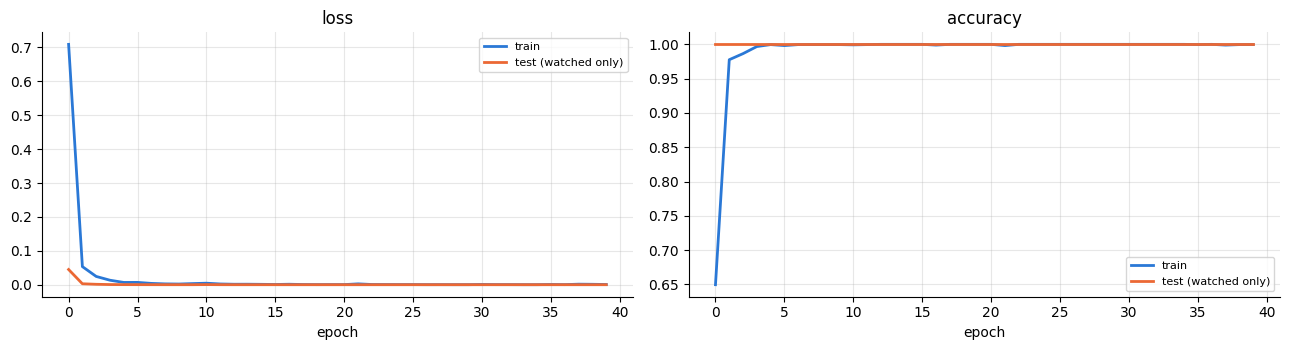

In [ ]:
counts = np.bincount(y_aug, minlength=len(LABELS))
class_weight = {i: len(y_aug) / (len(LABELS) * c) for i, c in enumerate(counts) if c > 0}

def show_progress(epoch, logs):
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"epoch {epoch + 1:3d}/{EPOCHS}   train accuracy {logs['accuracy']:.3f}   "
              f"test accuracy {logs['val_accuracy']:.3f}   train loss {logs['loss']:.4f}")

history = cnn.fit(X_aug, y_aug, epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight,
                  validation_data=(Xn_test, y_test_id), verbose=0,
                  callbacks=[keras.callbacks.LambdaCallback(on_epoch_end=show_progress)])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, metric in zip(axes, ['loss', 'accuracy']):
    ax.plot(history.history[metric], color='#2a78d6', lw=2, label='train')
    ax.plot(history.history['val_' + metric], color='#eb6834', lw=2, label='test (watched only)')
    ax.set_title(metric); ax.set_xlabel('epoch'); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

**Reading the curves:** loss should go down and accuracy up. If the training curve keeps improving while the test curve gets worse, the model is **over-fitting** (memorising): try more augmentation, fewer epochs or a smaller network. If neither curve improves, try more epochs or a larger learning rate.

---
## Part 4: Model testing



### 4.1 Results on the test files

Both models predict the movement of every test window. Rows of the confusion matrix are the true movement, columns the prediction; the diagonal is correct.

> ⚠️ If your test files are **copies of the training files** (the check in Part 1.1 tells you), the scores below only prove that the pipeline works. Real performance can only be measured on a **separately recorded** trial.

ℹ️ All test files are copies of training files: expect (near) perfect scores.

Random Forest test accuracy: 100.0%
CNN test accuracy:           100.0%

CNN per movement:
                           precision    recall  f1-score   support

L_HIP_ABDUCTION_ADDUCTION       1.00      1.00      1.00        27
  L_HIP_FLEXION_EXTENSION       1.00      1.00      1.00        42
                   L_JUMP       1.00      1.00      1.00        18
R_HIP_ABDUCTION_ADDUCTION       1.00      1.00      1.00        39
  R_HIP_FLEXION_EXTENSION       1.00      1.00      1.00        44
                   R_JUMP       1.00      1.00      1.00        59
                    SQUAT       1.00      1.00      1.00        25
                   STATIC       1.00      1.00      1.00        60

                 accuracy                           1.00       314
                macro avg       1.00      1.00      1.00       314
             weighted avg       1.00      1.00      1.00       314



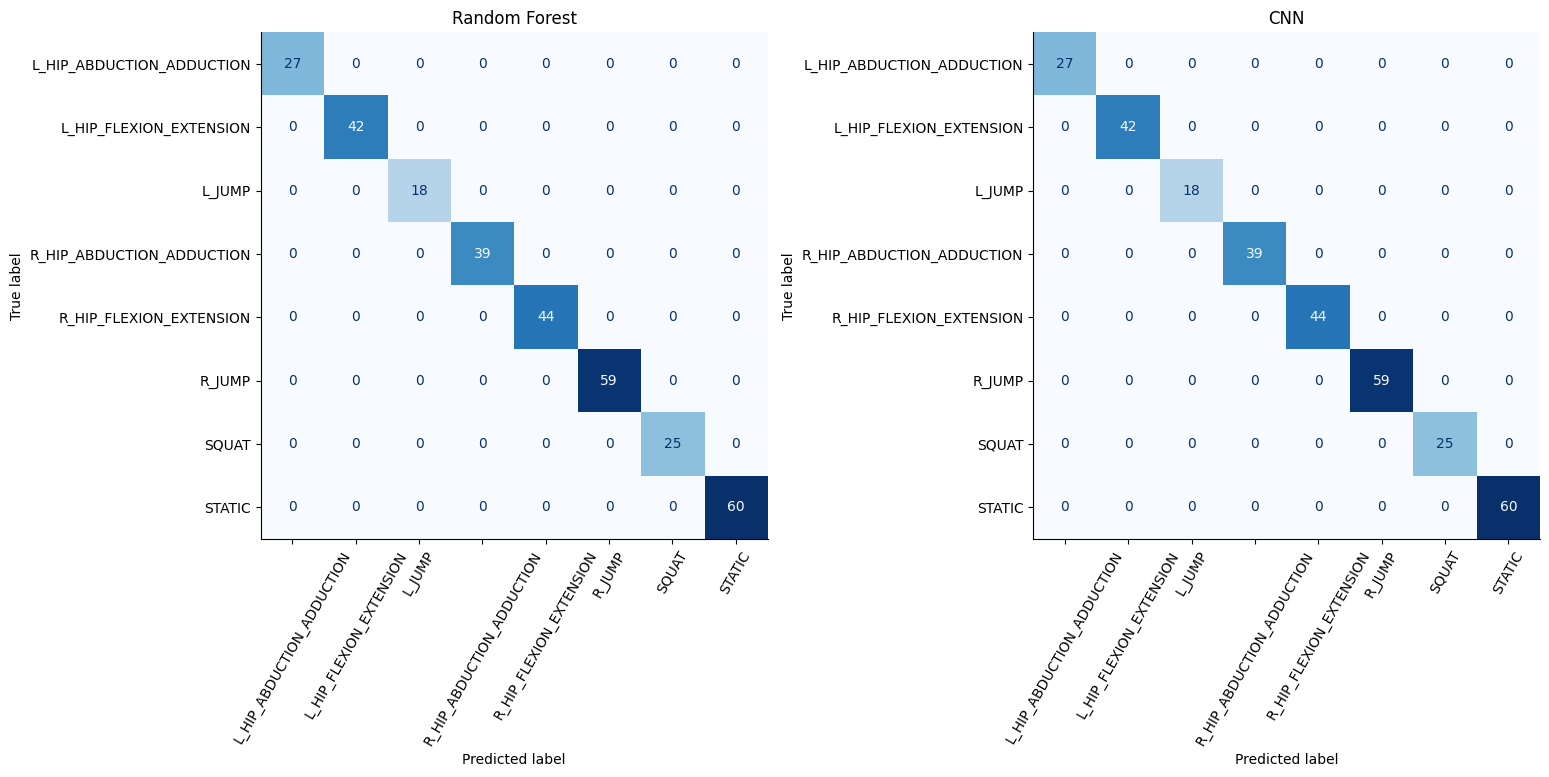

In [ ]:
if TEST_IS_COPY:
    print('ℹ️ All test files are copies of training files: expect (near) perfect scores.\n')

rf_pred = rf_model.predict(F_test)
cnn_pred = np.array(LABELS)[cnn.predict(Xn_test, verbose=0).argmax(axis=1)]
print(f'Random Forest test accuracy: {accuracy_score(y_test, rf_pred):.1%}')
print(f'CNN test accuracy:           {accuracy_score(y_test, cnn_pred):.1%}\n')
print('CNN per movement:')
print(classification_report(y_test, cnn_pred, labels=sorted(set(y_test)), zero_division=0))

size = 0.6 * len(LABELS) + 3
fig, axes = plt.subplots(1, 2, figsize=(2 * size, size))
for ax, pred, title in [(axes[0], rf_pred, 'Random Forest'), (axes[1], cnn_pred, 'CNN')]:
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=LABELS, cmap='Blues',
                                            xticks_rotation=60, colorbar=False, ax=ax)
    ax.grid(False); ax.set_title(title)
fig.tight_layout(); plt.show()

### 4.2 Limitations and suggestions for the hackathon

* **More data beats a fancier model.** Record more trials and more people. Test on a trial (or a person) the model has never seen.
* **Similar movements** (same leg, different direction) are the hardest. Try a longer `WINDOW_S`, more augmentation, or other sensor positions.
* **Fewer sensors:** use the importance plot and `SENSORS_TO_USE` to find the smallest set of sensors that still works. Fewer sensors = a more practical product.
* **Tune the CNN:** change the number of filters, `kernel_size`, add a layer, or try an LSTM (`layers.LSTM(64)`) instead of the convolution layers.
* **Filtering:** compare results for different `FILTER_CUTOFF_HZ` values.
* **Real time:** the window-by-window prediction in 4.2 is the basis of a live detector.